## Import Data 

Load data from CSV and print out basic information

In [19]:
import pandas as pd
import numpy as np

df = pd.read_csv('student_grade_ses_dataset.csv')

# Provide idea of the dataframe we are dealing with 
print(df.info())
print(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 12025 entries, 0 to 12024
Data columns (total 29 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   student_id                  12025 non-null  str    
 1   academic_year               12025 non-null  str    
 2   survey_date                 12025 non-null  str    
 3   age                         12025 non-null  int64  
 4   gender                      12025 non-null  str    
 5   grade_level                 12025 non-null  int64  
 6   school_type                 12025 non-null  str    
 7   residence_type              12025 non-null  str    
 8   family_size                 12025 non-null  int64  
 9   num_siblings                12025 non-null  int64  
 10  single_parent_household     12025 non-null  int64  
 11  family_income_bracket       12025 non-null  str    
 12  annual_family_income_inr    11304 non-null  float64
 13  father_education_level      11605 non-null

## Data Preprocessing: First steps

First initial steps in data preprocessing: removing duplicates and setting index columns. 

In [20]:
# 1. Cleaning Duplicate Rows 
duplicates = df[df.duplicated()]
print("Duplicate Rows:")
print(duplicates)

row_count_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
row_count_after = len(df)
print(f"{row_count_before} rows -> {row_count_after} after removing duplicates")

# 2. Set 'student_id' as the index and drop it from the standard columns
is_all_unique = df['student_id'].is_unique
print(f"Column student_id uniqueness: {is_all_unique}")
df = df.set_index('student_id', drop=True)

Duplicate Rows:
      student_id academic_year survey_date  age  gender  grade_level  \
2052   STU100247     2024-2025     10/3/25   13    Male            8   
2323   STU111139     2023-2024      5/3/25   17  Female           12   
4406   STU107482     2022-2023      1/5/25   14   Other            9   
5645   STU110619     2023-2024      8/5/25   11    Male            7   
5715   STU104160     2022-2023     12/5/25   13  Female            8   
5801   STU108370     2022-2023     22/3/25   18    Male           12   
6089   STU100191     2022-2023      8/3/25   15  Female           10   
6099   STU108270     2021-2022     16/4/25   12    Male            8   
7395   STU111279     2024-2025     19/4/25   15  Female            9   
7700   STU101857     2021-2022     10/5/25   14  Female           10   
7788   STU108388     2021-2022     10/4/25   18  Female           12   
7902   STU104036     2022-2023      3/4/25   14  Female           10   
7990   STU105705     2023-2024      7/3/25   15 

## Data Preprocessing: Missing data analysis 

Initial analysis on missing data and NaN cells to understand their missing pattern (random / pattern). 

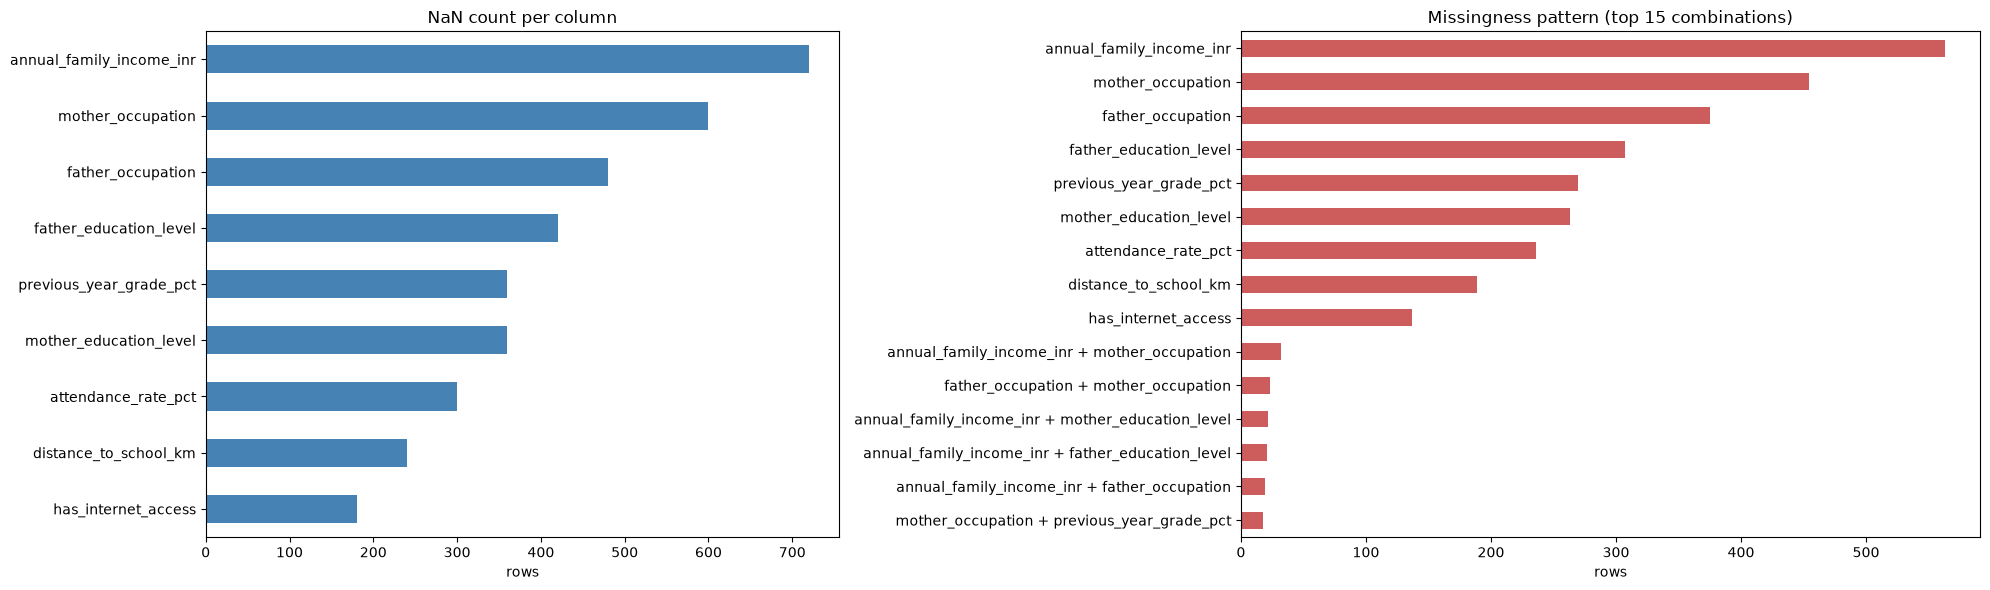

annual_family_income_inr                             563
mother_occupation                                    454
father_occupation                                    375
father_education_level                               307
previous_year_grade_pct                              270
mother_education_level                               263
attendance_rate_pct                                  236
distance_to_school_km                                189
has_internet_access                                  137
annual_family_income_inr + mother_occupation          32
father_occupation + mother_occupation                 23
annual_family_income_inr + mother_education_level     22
annual_family_income_inr + father_education_level     21
annual_family_income_inr + father_occupation          19
mother_occupation + previous_year_grade_pct           18
Name: count, dtype: int64


In [21]:
import matplotlib.pyplot as plt

na = df.isna()
cols = na.columns[na.any()]
na = na[cols]

fig, axes = plt.subplots(1, 2, figsize=(20, 6), gridspec_kw={'width_ratios': [1.2, 1.4]})

# 1. NaN count per column
na.sum().sort_values().plot.barh(ax=axes[0], color='steelblue')
axes[0].set_title('NaN count per column')
axes[0].set_xlabel('rows')

# 2. Missingness pattern: which combinations of columns are missing together
pattern = na[na.any(axis=1)].apply(lambda r: ' + '.join(r.index[r]), axis=1).value_counts()
pattern.head(15).sort_values().plot.barh(ax=axes[1], color='indianred')
axes[1].set_title('Missingness pattern (top 15 combinations)')
axes[1].set_xlabel('rows')

plt.tight_layout()
plt.show()

print(pattern.head(15))

## Data Preprocessing: Imputing Missing values
Missing parent occupations look random (students with an unknown occupation have about the same average grade as everyone else), so they become their own "Unknown" category. This learns nothing from the data, so it is safe to do before the train/test split.

Every other missing value is filled by the `GroupImputer` below.

In [22]:
parent_cols = ['father_occupation', 'mother_occupation']
df[parent_cols] = df[parent_cols].fillna("Unknown")
nulls = df.isna().sum()
nulls[nulls > 0]

annual_family_income_inr    720
father_education_level      420
mother_education_level      360
has_internet_access         180
distance_to_school_km       240
attendance_rate_pct         300
previous_year_grade_pct     360
dtype: int64

## Data Preprocessing: Filling the rest

Fill values have to come from training rows only.
The `GroupImputer` does a fit and transform inside each CV fold.

| Column | Fill with | Why |
|---|---|---|
| `annual_family_income_inr` | median per `family_income_bracket`| bracket is complete and tracks income closely (r = 0.96 with log income, checked below; Low (103k) vs High (3M)); the overall median (~350k) would put a high-income family in the middle |
| `distance_to_school_km` | median per `residence_type` | Rural (5.4 km) vs Urban (1.7 km) |
| `has_internet_access` | most common value per `residence_type`| Rural (36%) vs Urban (60%); the overall mode would give everyone 0 |
| `father_education_level`, `mother_education_level` | most common level per `family_income_bracket` | education rises with income (r = 0.52): the most common level goes from Primary in the Low bracket to Master's Degree in the High bracket |
| `attendance_rate_pct`, `previous_year_grade_pct` | overall median | nothing else predicts them well (correlation <= 0.29) |

Rows with these missing values have about the same final grade as complete rows, so the gaps look random and simple filling is reasonable. `family_income_bracket` is dropped once income and education are filled: it is only a banded version of income, so it adds nothing as a predictor.

In [23]:
# family_income_bracket is a banded version of annual_family_income_inr, so check how closely they match
bracket_rank = df['family_income_bracket'].map({'Low': 0, 'Lower-Middle': 1, 'Middle': 2, 'Upper-Middle': 3, 'High': 4})
log_income = np.log1p(df['annual_family_income_inr'])

print(f'Correlation between family_income_bracket and log income: r = {bracket_rank.corr(log_income):.2f}')

Correlation between family_income_bracket and log income: r = 0.96


In [24]:
from sklearn.base import BaseEstimator, TransformerMixin

class GroupImputer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        # income -> median of income bracket
        self.income_medians_ = X.groupby("family_income_bracket")["annual_family_income_inr"].median()

        # distance -> median of residence type
        self.distance_medians_ = X.groupby("residence_type")["distance_to_school_km"].median()

        # internet -> most common value for residence type
        internet = X.groupby("residence_type")["has_internet_access"]
        self.internet_modes_ = internet.agg(lambda s : s.mode()[0])

        # parent education level -> most common level of the income bracket
        father_edu = X.groupby("family_income_bracket")['father_education_level']
        mother_edu = X.groupby("family_income_bracket")['mother_education_level']
        self.father_edu_modes_ = father_edu.agg(lambda s: s.mode()[0])
        self.mother_edu_modes_ = mother_edu.agg(lambda s: s.mode()[0])

        # attendance and previous grade -> overall median
        self.other_medians_ = X[['attendance_rate_pct', 'previous_year_grade_pct']].median()

        self.columns_ = list(X.columns)

        return self

    def transform(self, X):
        X = X.copy()

        income_fill = X["family_income_bracket"].map(self.income_medians_)
        X["annual_family_income_inr"] = X["annual_family_income_inr"].fillna(income_fill)

        distance_fill = X["residence_type"].map(self.distance_medians_)
        X["distance_to_school_km"] = X["distance_to_school_km"].fillna(distance_fill)

        internet_fills = X["residence_type"].map(self.internet_modes_)
        X["has_internet_access"] = X["has_internet_access"].fillna(internet_fills)

        father_fill = X['family_income_bracket'].map(self.father_edu_modes_)
        X['father_education_level'] = X['father_education_level'].fillna(father_fill)

        mother_fill = X['family_income_bracket'].map(self.mother_edu_modes_)
        X['mother_education_level'] = X['mother_education_level'].fillna(mother_fill)

        X = X.fillna(self.other_medians_)

        return X

    def get_feature_names_out(self, input_features=None):
        return self.columns_

## Data Preprocessing: Visualisation of datatypes

Describe the data visually to get a lay of the land and the data types that we are working with. 

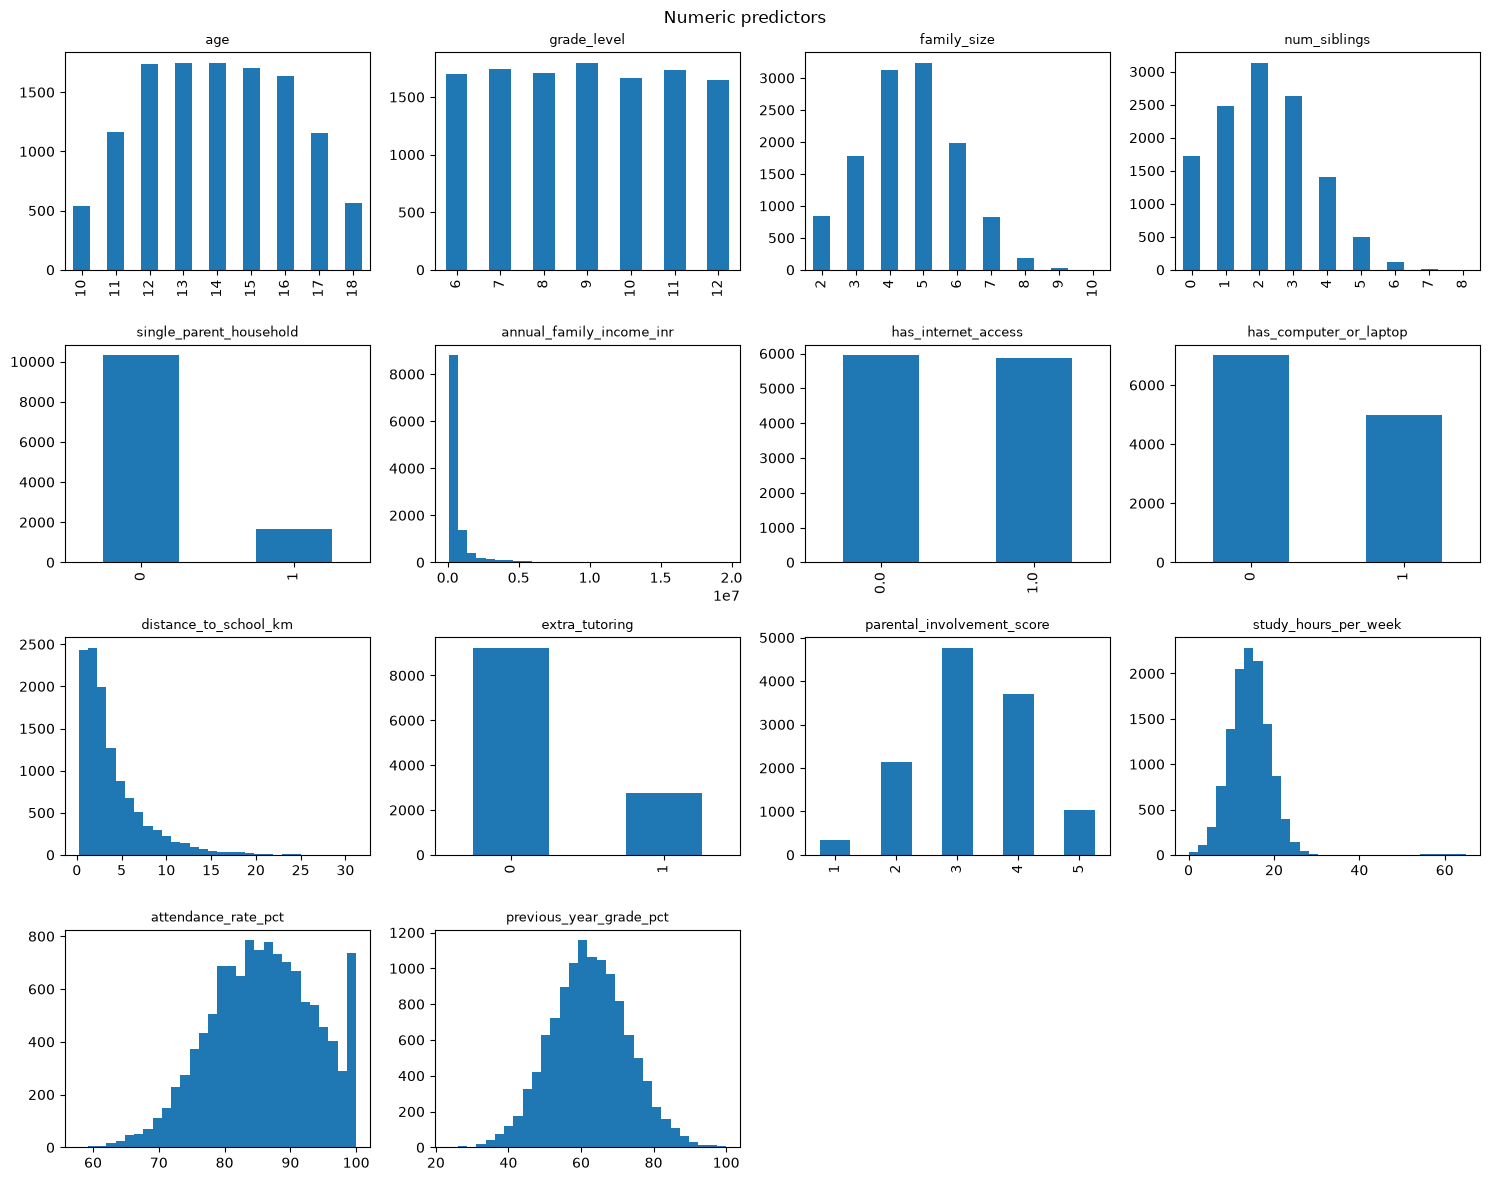

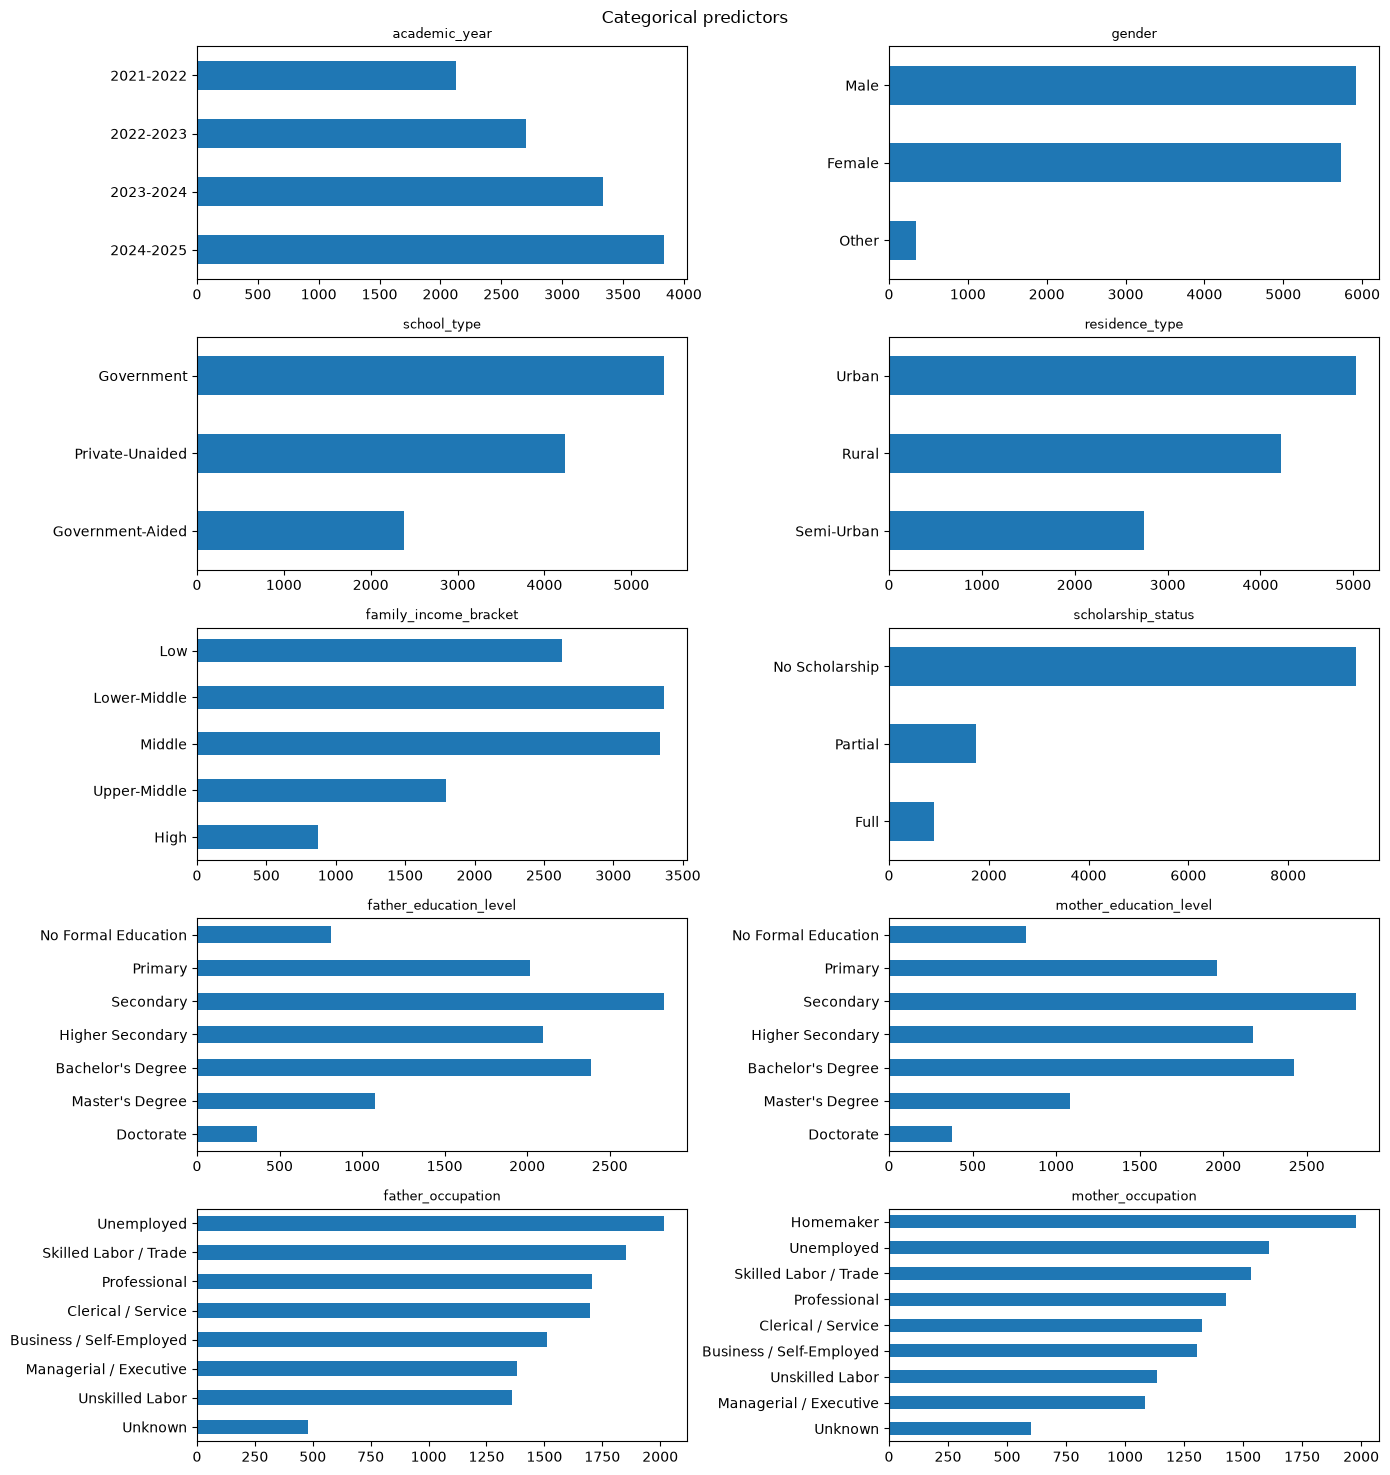

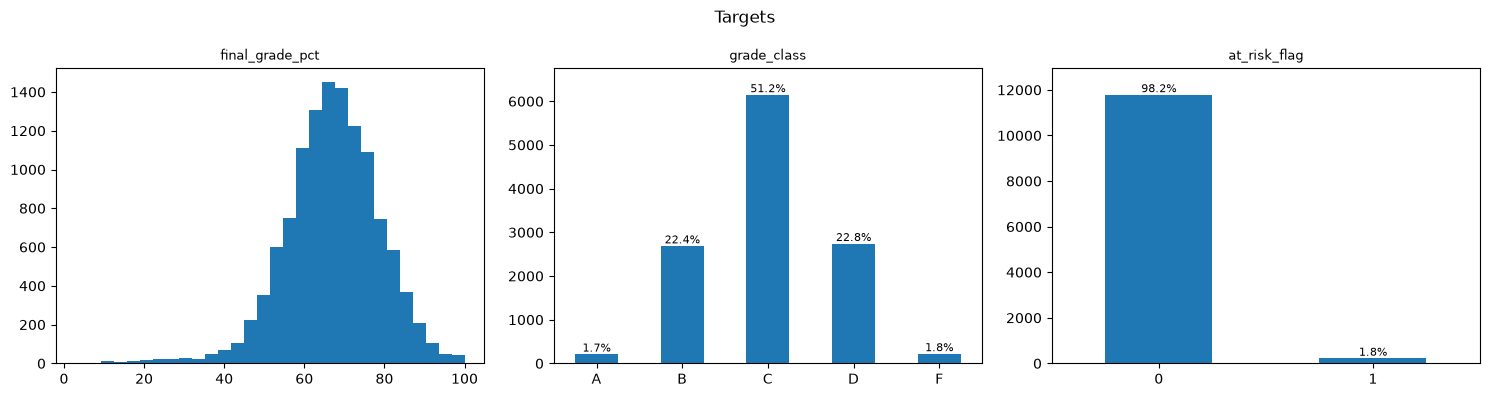

In [25]:
# Visualisation of predictors and targets

TARGET_COLS = ['final_grade_pct', 'grade_class', 'at_risk_flag']


# Figure 1: numeric predictors
numeric_predictors = df.select_dtypes('number').columns.drop(TARGET_COLS, errors='ignore')

fig, axes = plt.subplots(4, 4, figsize=(15, 12))
axes = axes.flatten()

for i, col in enumerate(numeric_predictors):
    ax = axes[i]
    if df[col].nunique() <= 10:
        df[col].value_counts().sort_index().plot(kind='bar', ax=ax)
        ax.set_xlabel('')
    else:
        df[col].hist(bins=30, ax=ax, grid=False)
    ax.set_title(col, fontsize=9)

for ax in axes[len(numeric_predictors):]:
    ax.set_visible(False)

fig.suptitle('Numeric predictors')
plt.tight_layout()
plt.show()

# ===========================================================================================================

# Figure 2: categorical predictors
# Columns with a natural order keep it; the others are sorted by count
EDUCATION_ORDER = [
    'No Formal Education',
    'Primary',
    'Secondary',
    'Higher Secondary',
    "Bachelor's Degree",
    "Master's Degree",
    'Doctorate',
]
CATEGORY_ORDERS = {
    'academic_year':            ['2021-2022', '2022-2023', '2023-2024', '2024-2025'],
    'family_income_bracket':    ['Low', 'Lower-Middle', 'Middle', 'Upper-Middle', 'High'],
    'father_education_level':   EDUCATION_ORDER,
    'mother_education_level':   EDUCATION_ORDER,
    'scholarship_status':       ['No Scholarship', 'Partial', 'Full'],
}
categorical_predictors = [
    'academic_year',
    'gender',
    'school_type',
    'residence_type',
    'family_income_bracket',
    'scholarship_status',
    'father_education_level',
    'mother_education_level',
    'father_occupation',
    'mother_occupation',
]

fig, axes = plt.subplots(5, 2, figsize=(14, 15))

for ax, col in zip(axes.flatten(), categorical_predictors):
    counts = df[col].value_counts()
    if col in CATEGORY_ORDERS:
        counts = counts.reindex(CATEGORY_ORDERS[col])
    counts.plot(kind='barh', ax=ax)
    ax.invert_yaxis()      # first category at the top
    ax.set_ylabel('')
    ax.set_title(col, fontsize=9)

fig.suptitle('Categorical predictors')
plt.tight_layout()
plt.show()

# ===========================================================================================================

# Figure 3: targets
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

df['final_grade_pct'].hist(bins=30, ax=axes[0], grid=False)
axes[0].set_title('final_grade_pct', fontsize=9)

grade_counts = df['grade_class'].value_counts().reindex(['A', 'B', 'C', 'D', 'F'])
at_risk_counts = df['at_risk_flag'].value_counts().sort_index()

for ax, counts, title in [(axes[1], grade_counts, 'grade_class'), (axes[2], at_risk_counts, 'at_risk_flag')]:
    counts.plot(kind='bar', ax=ax, rot=0)
    ax.bar_label(ax.containers[0], labels=[f'{count / len(df):.1%}' for count in counts], fontsize=8)
    ax.margins(y=0.1)      # room for the labels above the tallest bar
    ax.set_xlabel('')
    ax.set_title(title, fontsize=9)

fig.suptitle('Targets')
plt.tight_layout()
plt.show()

## Data Preprocessing: Skewed income column

From the figures, `annual_family_income_inr` is very right-skewed (skew 4.5): a few very rich families stretch the axis while most families sit at the low end. We log transform it later in the data prep pipeline because:

- Grades rise in a straight line with log income, not raw income. On its own, log income explains more of the variation in final grade than raw income (R² 0.120 vs 0.082), so linear and logistic regression fit it better.
- It stops a few ultra-rich families from having a big pull on the fitted line in the linear models, and on the distances used by k-NN, SVM and K-means.
- The log keeps the order of incomes, so tree models (which only use the order) are not affected.

`study_hours_per_week` and `distance_to_school_km` are also skewed (skew about 2), but we do not log them because it does not help: for study hours, R² is 0.052 raw vs 0.049 logged, and distance has no relationship with final grade either way.

In [26]:
print(f"annual_family_income_inr skew: {df['annual_family_income_inr'].skew()}")
print(f"log_income skew: {np.log1p(df['annual_family_income_inr']).skew()}")

from sklearn.preprocessing import FunctionTransformer

def log_transform():
    return FunctionTransformer(
        np.log1p,
        feature_names_out="one-to-one"
    )

annual_family_income_inr skew: 4.530329465806571
log_income skew: 0.4205498391130807


## Data Preprocessing: Schema Setup

Based off the visuals above, we can see clearly which of the columns are discrete/continuous/categorical and form the column schema below. Under categorical columns, we further observe which columns have a natural ordering (ordinal) and which doesn't (one-hot). 

In [27]:
# Schema Setup 

REGRESSION_TARGET     = 'final_grade_pct'
CLASSIFICATION_TARGET = 'at_risk_flag'

# Continuous values 
CONTINUOUS_COLS = [
    'distance_to_school_km', 
    'study_hours_per_week', 
    'attendance_rate_pct',          
    'previous_year_grade_pct', 
    'annual_family_income_inr'
]

# Integer labels
DISCRETE_COLS = [
    'age', 
    'grade_level', 
    'family_size', 
    'num_siblings', 
    'single_parent_household',
    'has_internet_access', 
    'has_computer_or_laptop', 
    'extra_tutoring',
    'parental_involvement_score'
]

# 0/1 indicators (part of DISCRETE_COLS): kept as 0/1 and not standardised, like the one-hot columns (as in the labs)
BINARY_COLS = [
    'single_parent_household',
    'has_internet_access',
    'has_computer_or_laptop',
    'extra_tutoring',
]

# Categorical columns - text labels
# No natural order: one-hot encoded
ONEHOT_COLUMNS = [
    'academic_year', 
    'gender', 
    'school_type', 
    'residence_type', 
    'father_occupation',
    'mother_occupation', 
]

# Clear order (lowest level first): ordinal encoded
EDUCATION_LEVELS = [
    'No Formal Education',
    'Primary',
    'Secondary',
    'Higher Secondary',
    "Bachelor's Degree",
    "Master's Degree",
    'Doctorate',
]

ORDINAL_COLUMNS = {
    'father_education_level': EDUCATION_LEVELS,
    'mother_education_level': EDUCATION_LEVELS,
    'scholarship_status':     ['No Scholarship', 'Partial', 'Full'],
}

# Only used by GroupImputer to fill missing income and parent education. The pipeline drops it before the models
IMPUTATION_ONLY_COLS = ['family_income_bracket']

CATEGORICAL_COLS = ONEHOT_COLUMNS + list(ORDINAL_COLUMNS)
NUMERIC_COLS = CONTINUOUS_COLS + DISCRETE_COLS
PREDICTOR_COLS = NUMERIC_COLS + CATEGORICAL_COLS    # columns the models use

# Setup X predictors
 
X = df[PREDICTOR_COLS + IMPUTATION_ONLY_COLS]    # predictors, plus the column GroupImputer needs
print('X:', X.shape)

X: (12000, 24)


## Data Preprocessing: Predictor correlations with the regression target

Pearson correlations show the direction and strength of each numeric predictor's linear association with `final_grade_pct`. Text categorical predictors are excluded, as in the predictor correlation heatmap below. Correlations use available predictor-target pairs (without imputation) across the deduplicated data and are descriptive, not evidence of causation.


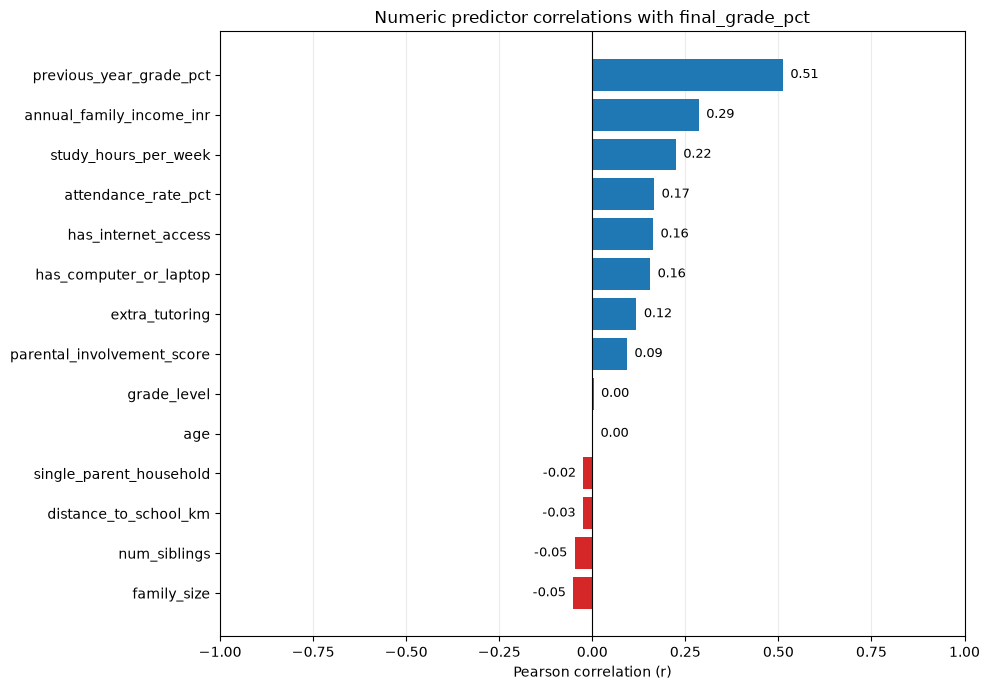

In [28]:
# Correlation of each numeric predictor with the regression target
# corrwith aligns rows and excludes missing predictor-target pairs.
target_correlations = X[NUMERIC_COLS].corrwith(df[REGRESSION_TARGET]).sort_values()

fig, ax = plt.subplots(figsize=(10, 7))
colors = ['tab:blue' if value >= 0 else 'tab:red' for value in target_correlations]
ax.barh(target_correlations.index, target_correlations.values, color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlim(-1, 1)
ax.set_xlabel('Pearson correlation (r)')
ax.set_title(f'Numeric predictor correlations with {REGRESSION_TARGET}')
ax.grid(axis='x', alpha=0.25)
ax.set_axisbelow(True)

for row, value in enumerate(target_correlations):
    if pd.notna(value):
        ax.text(value + (0.02 if value >= 0 else -0.02), row, f'{value:.2f}',
                va='center', ha='left' if value >= 0 else 'right', fontsize=9)

plt.tight_layout()
plt.show()


### Predictor relationships with the regression target (TODO: Cleanup)

Continuous predictors use scatterplots, with each point representing a student. Discrete predictors (from `age` through `parental_involvement_score`, including binary flags) use box plots of `final_grade_pct` at each observed level. Boxes show the middle 50% of grades and the median; whiskers extend to the most extreme values within 1.5 times the interquartile range, and points beyond them are shown individually.

Each panel reports Pearson's r using available predictor-target pairs. Income uses a logarithmic horizontal axis to make its skewed distribution easier to see; its reported correlation still uses the original income values.

Scatterplots include a least-squares fit and a shaded band of ±1 residual standard deviation in grade percentage points, estimated as `sqrt(sum(residuals**2) / (n - 2))`. The band describes scatter around the fit, rather than a confidence interval for the mean. Fits use the original predictor values, so the income fit appears curved on its logarithmic axis.


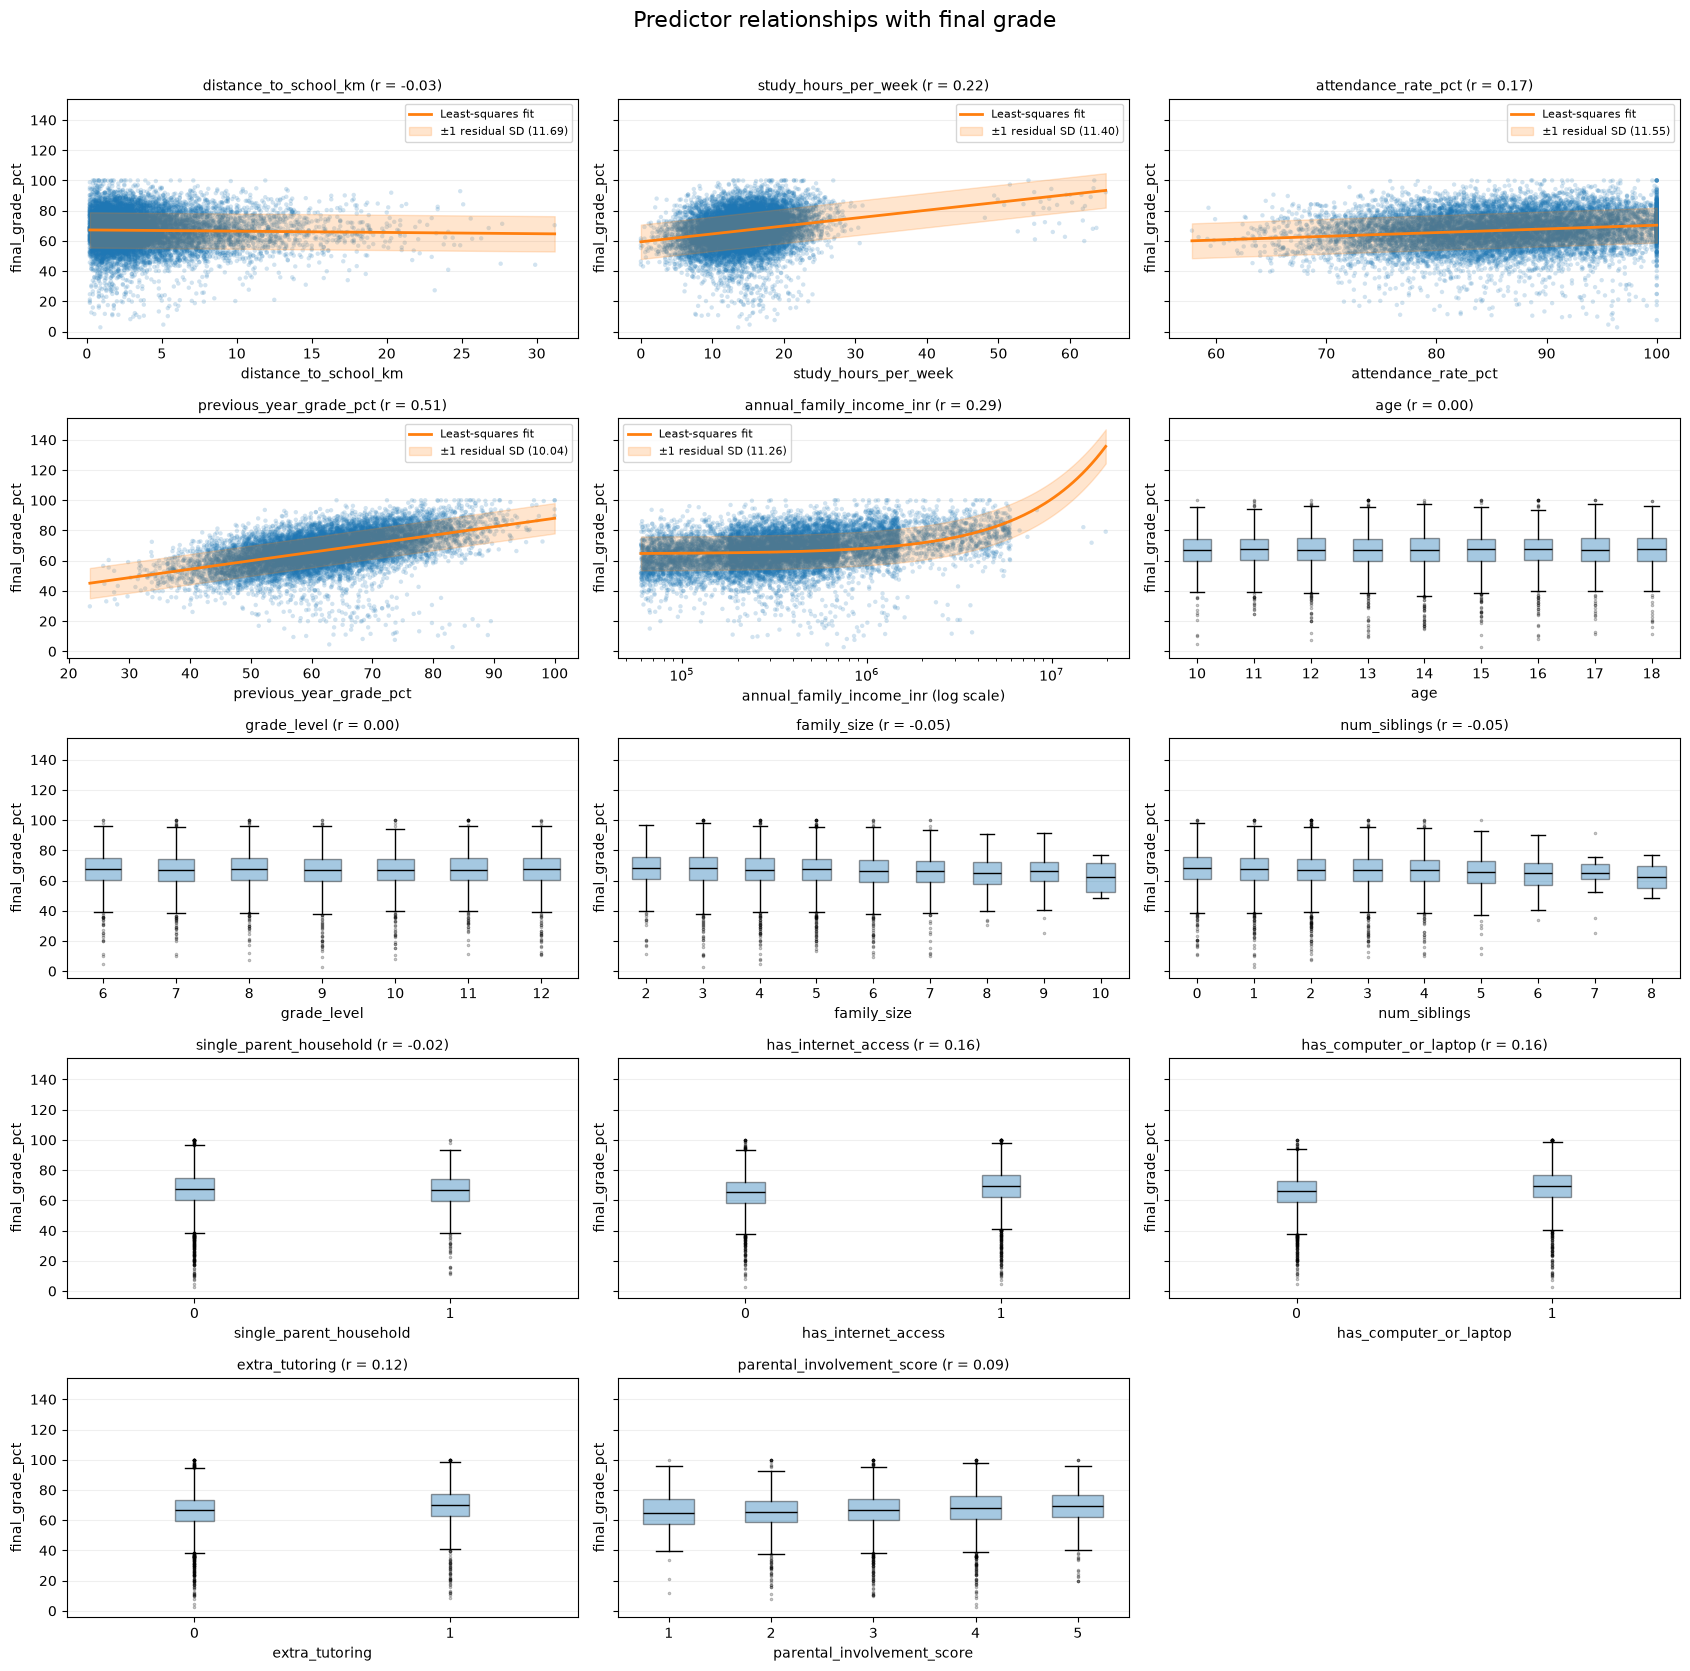

In [29]:
# Scatterplots for continuous predictors; box plots for discrete predictors.
ncols = 3
nrows = (len(NUMERIC_COLS) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(17, 3.4 * nrows),
                         sharey=True, squeeze=False)

for ax, predictor in zip(axes.flat, NUMERIC_COLS):
    pairs = pd.concat([X[predictor], df[REGRESSION_TARGET]], axis=1).dropna()
    if predictor in DISCRETE_COLS:
        levels = sorted(pairs[predictor].unique())
        grade_groups = [pairs.loc[pairs[predictor] == level, REGRESSION_TARGET]
                        for level in levels]
        positions = np.arange(1, len(levels) + 1)
        ax.boxplot(grade_groups, positions=positions, patch_artist=True,
                   boxprops={'facecolor': 'tab:blue', 'alpha': 0.4},
                   medianprops={'color': 'black'},
                   flierprops={'marker': '.', 'markersize': 3, 'alpha': 0.3})
        ax.set_xticks(positions, [f'{level:g}' for level in levels])
    else:
        ax.scatter(pairs[predictor], pairs[REGRESSION_TARGET],
                   s=10, alpha=0.2, edgecolors='none', rasterized=True)
        x_values = pairs[predictor].to_numpy(dtype=float)
        y_values = pairs[REGRESSION_TARGET].to_numpy(dtype=float)
        if len(pairs) > 2 and pairs[predictor].nunique() > 1:
            slope, intercept = np.polyfit(x_values, y_values, deg=1)
            residuals = y_values - (slope * x_values + intercept)
            residual_sd = np.sqrt(np.sum(residuals ** 2) / (len(pairs) - 2))
            # Sample evenly on the displayed axis; fit uses original predictor units.
            if predictor == 'annual_family_income_inr':
                x_fit = np.geomspace(x_values.min(), x_values.max(), 200)
            else:
                x_fit = np.linspace(x_values.min(), x_values.max(), 200)
            y_fit = slope * x_fit + intercept
            ax.plot(x_fit, y_fit, color='tab:orange', linewidth=2,
                    label='Least-squares fit')
            ax.fill_between(x_fit, y_fit - residual_sd, y_fit + residual_sd,
                            color='tab:orange', alpha=0.2,
                            label=f'±1 residual SD ({residual_sd:.2f})')
            ax.legend(fontsize=8, loc='best')
    r = pairs[predictor].corr(pairs[REGRESSION_TARGET])
    ax.set_title(f'{predictor} (r = {r:.2f})', fontsize=10)
    ax.set_xlabel(predictor)
    ax.set_ylabel(REGRESSION_TARGET)
    ax.grid(axis='y', alpha=0.2)
    ax.set_axisbelow(True)
    if predictor == 'annual_family_income_inr':
        ax.set_xscale('log')
        ax.set_xlabel(f'{predictor} (log scale)')

for ax in axes.flat[len(NUMERIC_COLS):]:
    ax.set_visible(False)

fig.suptitle('Predictor relationships with final grade', fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


## Data Preprocessing: Highly Correlated Predictors 

Address problems of collinearity to prevent highly correlated factors from affecting estimation of regression coefficients and hence statistical inference and predictive reliability.


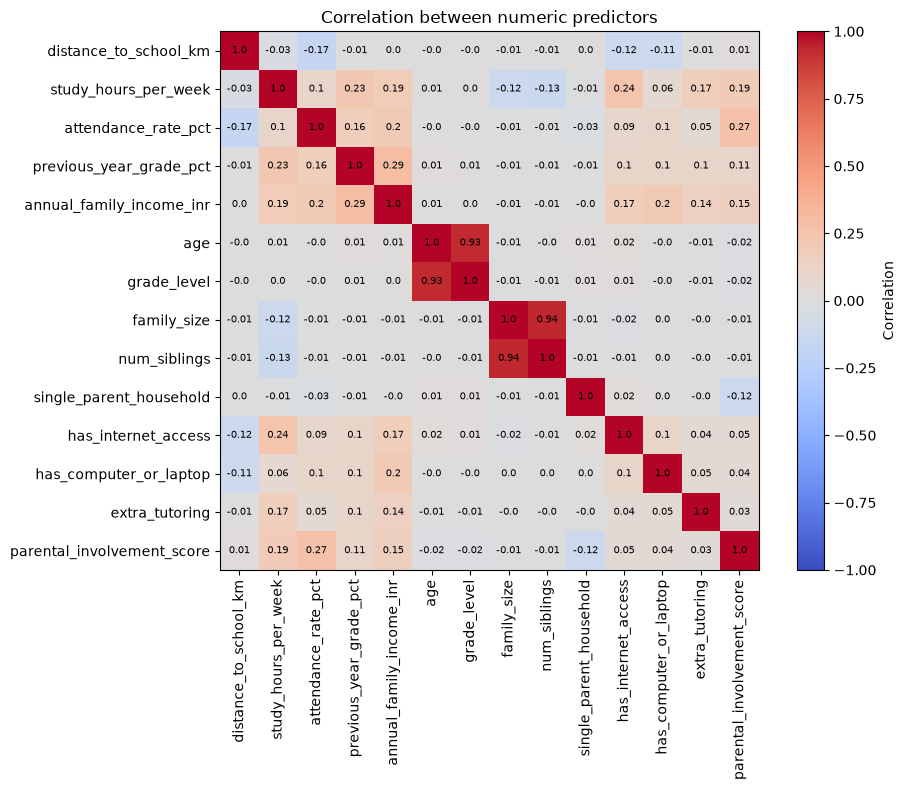

In [30]:
# Correlation heatmap of the numeric predictors
# (categorical columns are text, so they are left out here)
corr = X[NUMERIC_COLS].corr()

plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='Correlation')
plt.xticks(range(len(corr)), corr.columns, rotation=90)
plt.yticks(range(len(corr)), corr.columns)

# write the correlation value in each square
for i in range(len(corr)):
    for j in range(len(corr)):
        plt.text(j, i, round(corr.iloc[i, j], 2), ha='center', va='center', fontsize=7)

plt.title('Correlation between numeric predictors')
plt.tight_layout()
plt.show()

From the heatmap, most predictors are only weakly correlated with each other. Two pairs stand out:

- `age` and `grade_level` (r = 0.93): students in the same grade are mostly the same age.
- `family_size` and `num_siblings` (r = 0.94): more siblings means a bigger family.

Keeping both columns of a pair gives the linear models the same information twice, which makes the OLS coefficients unstable. So we drop one column from each pair:

- Keep `grade_level`, drop `age`. Grade level tells us which curriculum the student is in, and age within a grade adds little: every student is 4, 5 or 6 years older than their grade level (about 4,000 students each), and the average final grade is the same for all three (66.8 to 67.1).
- Keep `family_size`, drop `num_siblings`. Family size also counts parents and other relatives, so it is the more general measure. Family size is always the number of siblings plus 2 or 3, so `num_siblings` adds almost nothing new.

We checked this with OLS on all the other predictors: adding either dropped column back does not improve the fit (F-test p = 0.17 for `age`, p = 0.23 for `num_siblings`).

In [31]:
# Drop one predictor from each highly correlated pair
DROP_COLS = ['age', 'num_siblings']

DISCRETE_COLS   = [c for c in DISCRETE_COLS if c not in DROP_COLS]
NUMERIC_COLS    = CONTINUOUS_COLS + DISCRETE_COLS
PREDICTOR_COLS  = NUMERIC_COLS + CATEGORICAL_COLS

X                = df[PREDICTOR_COLS + IMPUTATION_ONLY_COLS]    # Shared predictors, plus the column GroupImputer needs
Y_regression     = df[REGRESSION_TARGET]                        # Regression target
Y_classification = df[CLASSIFICATION_TARGET]                    # Classification target 

print('Dropped:', DROP_COLS)
print('X:', X.shape)

Dropped: ['age', 'num_siblings']
X: (12000, 22)


## Data Preprocessing: Data Preparation Pipelines

Every model gets the same steps, fitted on the training rows only (inside each CV fold), so nothing leaks from the test set:

1. Fill missing values with the `GroupImputer`.
2. Encode the categories: one-hot (first level dropped) for unordered ones, ordinal codes for parent education and scholarship.
3. Log transform income.
4. Standardise, only for the models that need it.

The GAM is the one exception to step 2: pygam needs each category as a single column of integer codes for its factor terms, so the GAM's prep (`make_gam_prep`) uses integer codes instead of one-hot, and does not standardise.

| Models | Standardise? | Why |
|---|---|---|
| OLS, Ridge, Lasso, logistic | Yes | the Ridge, Lasso and logistic penalties depend on each column's scale (OLS is not affected, so it does no harm) |
| k-NN, SVM | Yes | they use distances, so a column with a big range would dominate |
| Decision tree, bagging, random forest, GBT | No | trees only use the order of the values, so scaling changes nothing |
| GAM | No | splines are fitted on each column's range, so standardising changes nothing |

The 0/1 columns (one-hot columns and the binary flags) are never standardised, as in the labs, so their coefficients read as "the effect of having it".

We checked the alternatives with 5-fold CV (one-hot instead of ordinal for education and scholarship, scaling the 0/1 columns, keeping the first one-hot level). None was clearly better (all within 0.01 RMSE for the linear models), and scaling the 0/1 columns made k-NN worse.

In [32]:
# Data preparation pipelines: the same steps for every model, with or without standardising

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

def build_prep(scale):
    # Standardise only for the models that need it
    scaler = StandardScaler() if scale else 'passthrough'

    # Each column goes through exactly one step
    # family_income_bracket is not listed, so it is dropped here (GroupImputer has already used it)
    encode_scale = ColumnTransformer([
        ('onehot',  OneHotEncoder(drop='first'), ONEHOT_COLUMNS),                                                                                  # Unordered categorical columns 
        ('ordinal', Pipeline([('encode', OrdinalEncoder(categories=list(ORDINAL_COLUMNS.values()))), ('scale', scaler)]), list(ORDINAL_COLUMNS)),  # Ordered categorical columns 
        ('income',  Pipeline([('log', log_transform()), ('scale', scaler)]), ['annual_family_income_inr']),                                        # Log transform income
        ('num',     scaler, [c for c in NUMERIC_COLS if c not in BINARY_COLS + ['annual_family_income_inr']]),                                     # Other continuous and discrete columns
        ('binary',  'passthrough', BINARY_COLS),                                                                                                   # Binary flags stay as 0/1, like the one-hot columns
    ])

    # Fill missing values, then encode and scale. Both are fitted on the training rows only
    return Pipeline([('impute', GroupImputer()), ('encode_scale', encode_scale)])


# Which version each model gets
def make_linear_prep():  # OLS, Ridge, Lasso, logistic: the penalty depends on each column's scale
    return build_prep(scale=True)

def make_knn_prep():     # k-NN: uses distances, so a column with a big range would dominate
    return build_prep(scale=True)

def make_svm_prep():     # SVM: the RBF kernel uses distances too
    return build_prep(scale=True)

def make_tree_prep():    # decision tree, bagging, random forest: trees only use the order of values, so no scaling
    return build_prep(scale=False)

def make_gbt_prep():     # gradient boosting: also trees, so no scaling
    return build_prep(scale=False)

# GAM: pygam needs each category as one column of integer codes (for its f() factor terms), so no one-hot and no scaling
def make_gam_prep():
    # Categories -> integer codes, learned on the training rows only
    # A label not seen in training becomes NaN, then is filled with the most common training level,
    # so the GAM only ever sees codes it was trained on (pygam raises an error on a new code)
    categorical = Pipeline([
        ("encode", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan)),
        ("unseen", SimpleImputer(strategy="most_frequent")),
    ])

    # Each column goes through exactly one step
    # family_income_bracket is not listed, so it is dropped here (GroupImputer has already used it)
    encode = ColumnTransformer([
        ("income", log_transform(), ["annual_family_income_inr"]),
        ("continuous", "passthrough", [c for c in CONTINUOUS_COLS if c != "annual_family_income_inr"]),
        ("discrete", "passthrough", DISCRETE_COLS),
        ("categorical", categorical, CATEGORICAL_COLS),
    ], verbose_feature_names_out=False)

    return Pipeline([("impute", GroupImputer()), ("encode", encode)]).set_output(transform="pandas")

## Data Preprocessing: Performance Test Metrics Helper Function

Setup respective performance metrics for upcoming regression and classification experiments. 

In [33]:
# Performance Test Metrics 

from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import cross_val_score

# Regression
def compute_test_metrics(fitted_model, X_train, Y_train, X_test, Y_test, cv_folds):
    # Returns (RMSE, MAE, R2, CV RMSE) of a fitted model on the test set
    test_predictions = fitted_model.predict(X_test)
    # CV RMSE on the training data: from the grid search if tuned, otherwise 5-fold cross_val_score
    if hasattr(fitted_model, 'best_score_'):
        cv_rmse = -fitted_model.best_score_
    else:
        cv_rmse = -cross_val_score(fitted_model, X_train, Y_train, cv=cv_folds, scoring='neg_root_mean_squared_error').mean()
    return (root_mean_squared_error(Y_test, test_predictions),
            mean_absolute_error(Y_test, test_predictions),
            r2_score(Y_test, test_predictions),
            cv_rmse)


# Classification
def compute_classification_test_metrics(fitted_search, X_test, Y_test):
    # Returns (AUC, CV AUC) of a fitted grid search on the test set
    # The test AUC uses the same roc_auc scoring as the tuning, and the CV AUC comes from the tuning on the training data
    return (fitted_search.score(X_test, Y_test),
            fitted_search.best_score_)

## GAM Regressor

| Term | Columns | Why |
|---|---|---|
| `s()` spline | `annual_family_income_inr` (logged), `distance_to_school_km`, `study_hours_per_week`, `attendance_rate_pct`, `previous_year_grade_pct` | Continuous, so the effect can curve |
| `l()` linear | `grade_level`, `family_size`, `parental_involvement_score` | Counts and scores with few distinct values, so a straight line is enough |
| `f()` factor | The 0/1 flags `single_parent_household`, `has_internet_access`, `has_computer_or_laptop`, `extra_tutoring` | Yes/no categories: one effect for “yes” vs. “no” (for a 0/1 column this gives the same fit as `l()`, but reads as a category, not a slope) |
| `f()` factor | `academic_year`, `gender`, `school_type`, `residence_type`, `father_occupation`, `mother_occupation`, `father_education_level`, `mother_education_level`, `scholarship_status` | Categories: each level gets its own effect |

Only the splines get the tuned lambda (spline_lam), which controls how curved they are. l() and f() keep pygam’s small default penalty (0.6), which barely matters with 10,000+ training rows.

In [34]:
from sklearn.base import BaseEstimator, RegressorMixin
from pygam import LinearGAM, s, l, f

class GAMRegressor(BaseEstimator, RegressorMixin):
    # Only the splines get the tuned lambda (spline_lam); l() and f() keep pygam's default
    def __init__(self, spline_lam=1.0):
        self.spline_lam = spline_lam

    def term_for(self, i, col):
        # BINARY_COLS is checked before DISCRETE_COLS because the 0/1 flags are in both
        if col in CONTINUOUS_COLS:
            return s(i, lam=self.spline_lam)
        if col in BINARY_COLS or col in CATEGORICAL_COLS:
            return f(i)
        if col in DISCRETE_COLS:
            return l(i)
        raise ValueError(f"GAMRegressor: no term type for column {col!r}")

    def fit(self, X, y):
        if not isinstance(X, pd.DataFrame):
            raise TypeError("GAMRegressor needs a DataFrame with column names (use make_gams_prep())")
        self.columns_ = list(X.columns)

        terms = None
        for i, col in enumerate(self.columns_):
            term = self.term_for(i, col)
            if terms is None:
                terms = term
            else:
                terms = terms + term

        self.gam_ = LinearGAM(terms)
        self.gam_.fit(X.to_numpy(dtype=float), np.asarray(y))
        return self

    def predict(self, X):
        # Use the training column order, so a reordered input still lines up with the fitted terms
        return self.gam_.predict(X[self.columns_].to_numpy(dtype=float))

# Main Experiment

In our experiment, we will be performing regression and classification prediction analysis according to the target columns defined. (Regression: `final_grade_pct`, Classification: `at_risk_flag`).

In the context of the schooling administration, what we would like to understand is what are the strongest predictors for student scores and grades. Beyond obvious predictors such as previous grade scores, are there other classes of predictors such as socioeconomic factors or technology access that help to predict student performance? 

In answering this question, we explore which model has stronger predictive performance and understand the nature of the underlying data (linear vs. nonlinear relationship). 

Practical Application: While regression analysis provides a fuller analysis on the underlying data, a school may care more about a practical question such as "which predictors are useful in identifying at-risk students?" than about an exact score percentage. Classification measures this directly, and lets us check whether the conclusions from the regression experiment still hold for the students most likely to fail.

---

It is important to note that it is possible to infer classification target, `at_risk_flag`, directly from our regression target, `final_grade_pct`, because the flag is simply a cut-off on the final grade:

| `at_risk_flag` | `final_grade_pct` |
|---|---|
| 1 (at risk) | below 40 | 
| 0 (not at risk) | 40 to 100 | 

Because both experiments are predicting the same outcome at different levels of detail (granularity), the classification results are not independent evidence. Regression is the main experiment as it's the fuller version of the problem. Classification reduces the same outcome to a single cut-off and so the results are coarser (as the cut-off loses information). However, the classification experiment is valuable for us to understand tail-end at-risk students better. 

In [ ]:
# Experiment settings: the knobs that control how long the pilot, regression and classification experiments take.
# For a quick test run, lower the counts (e.g. NUMBER_OF_EXPERIMENTS = 2, OUTER_REPEATS = 1), then set them back before the final run.
# All results and conclusions in this notebook are based on the full settings below.
from sklearn.model_selection import RepeatedStratifiedKFold

INNER_FOLDS = 5                 # K-fold CV inside GridSearchCV, used to tune every model (pilot, regression and classification)

# Regression 
TEST_SIZE             = 0.15    # 85/15 train-test split
NUMBER_OF_EXPERIMENTS = 20      # Each experiment = new random 85/15 split, tune every model, score on the test set. 20 runs for the paired t-tests

# Classification 
# Outer splits: 5-fold stratified CV repeated 4 times = 20 train/test splits (80/20)
# At-risk students are rare, so K-fold makes sure every one of them is in a test set once per repeat
OUTER_FOLDS   = 5
OUTER_REPEATS = 4
outer_cv = RepeatedStratifiedKFold(n_splits=OUTER_FOLDS, n_repeats=OUTER_REPEATS, random_state=0)
NUMBER_OF_CLASS_EXPERIMENTS = OUTER_FOLDS * OUTER_REPEATS


## Stage 1: Hyperparameter Tuning Pilot Run: Coarse-to-Fine Search
The upcoming main regression experiment below repeats a full grid search 20 times, so searching a large grid each time would be computationally expensive (curse of dimensionality). 

To reduce this cost, a coarse-to-fine search is used: a one-off search over a wide, roughly log-spaced grid of values for each model, evaluated with 5-fold cross-validation on the training data only. The best value and its neighbours form a narrower grid, which the main experiment uses for its tuning.

In [36]:
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

X_pilot, _, Y_pilot, _ = train_test_split(X, Y_regression, test_size=TEST_SIZE, random_state=0, shuffle=True)
pilot_cv = KFold(n_splits=INNER_FOLDS, shuffle=True, random_state=0)

# Wide grids
wide_ridge_grid         = {'model__alpha':            [0.1, 1, 3, 10, 30, 100, 300, 1000, 3000]}
wide_lasso_grid         = {'model__alpha':            [0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1]}
wide_knn_grid           = {'model__n_neighbors':      [5, 10, 25, 50, 100, 200, 400],
                           'model__weights':          ['uniform', 'distance']}
wide_decision_tree_grid = {'model__max_depth':        [2, 3, 4, 6, 8, 10, 15],
                           'model__min_samples_leaf': [5, 10, 20, 50, 100, 200, 400]}
wide_random_forest_grid = {'model__max_features':     [0.1, 0.2, 0.33, 0.5, 0.8, 1.0],
                           'model__min_samples_leaf': [1, 5, 10, 20, 40, 80]}
wide_gbt_grid           = {'model__learning_rate':    [0.01, 0.02, 0.05, 0.1, 0.2, 0.4],
                           'model__max_depth':        [1, 2, 3, 4, 6],
                           'model__min_samples_leaf': [2, 5, 10, 20, 50, 100, 200]}
wide_gam_grid           = { 'model__spline_lam':      [0.1, 1, 10, 100, 1000, 10000, 100000] }

# Name: (pipeline, wide grid)
pilot_models = {
    'Ridge':          (Pipeline([('prep', make_linear_prep()), ('model', Ridge())]),                                                                            wide_ridge_grid),
    'Lasso':          (Pipeline([('prep', make_linear_prep()), ('model', Lasso(max_iter=10000))]),                                                              wide_lasso_grid),
    'k-NN':           (Pipeline([('prep', make_knn_prep()),    ('model', KNeighborsRegressor())]),                                                              wide_knn_grid),
    'Decision tree':  (Pipeline([('prep', make_tree_prep()),   ('model', DecisionTreeRegressor(random_state=0))]),                                              wide_decision_tree_grid),
    'Random forest':  (Pipeline([('prep', make_tree_prep()),   ('model', RandomForestRegressor(n_estimators=100, random_state=0))]),                            wide_random_forest_grid),
    'GBT':            (Pipeline([('prep', make_gbt_prep()),    ('model', GradientBoostingRegressor(n_estimators=500, n_iter_no_change=10, random_state=0))]),   wide_gbt_grid),
    'GAM':            (Pipeline([('prep', make_gam_prep()),    ('model', GAMRegressor())]),                                                                     wide_gam_grid)
}

def narrow(values, best_value):
    # keep the best value and one neighbour on each side
    i = values.index(best_value)
    return values[max(i - 1, 0): i + 2]

pilot_results = {}
best_values   = {}
final_grids   = {}

for name, (pipe, grid) in pilot_models.items():
    search = GridSearchCV(pipe, grid, cv=pilot_cv, scoring='neg_root_mean_squared_error',
                          n_jobs=1 if name == 'GAM' else -1)
    search.fit(X_pilot, Y_pilot)
    pilot_results[name] = pd.DataFrame(search.cv_results_)
    best_values[name]   = search.best_params_
    final_grids[name]   = {}

    print(f'{name}: best CV RMSE = {-search.best_score_:.3f}')
    for param, values in grid.items():
        best = search.best_params_[param]
        if isinstance(values[0], str):      # text options (weights) are kept as they are
            final_grids[name][param] = values
        else:
            final_grids[name][param] = narrow(values, best)
        print(f'{param}: best = {best}, final grid = {final_grids[name][param]}')

Ridge: best CV RMSE = 9.669
model__alpha: best = 300, final grid = [100, 300, 1000]
Lasso: best CV RMSE = 9.659
model__alpha: best = 0.03, final grid = [0.01, 0.03, 0.1]
k-NN: best CV RMSE = 9.994
model__n_neighbors: best = 100, final grid = [50, 100, 200]
model__weights: best = distance, final grid = ['uniform', 'distance']
Decision tree: best CV RMSE = 10.030
model__max_depth: best = 6, final grid = [4, 6, 8]
model__min_samples_leaf: best = 100, final grid = [50, 100, 200]
Random forest: best CV RMSE = 9.799
model__max_features: best = 0.33, final grid = [0.2, 0.33, 0.5]
model__min_samples_leaf: best = 20, final grid = [10, 20, 40]
GBT: best CV RMSE = 9.711
model__learning_rate: best = 0.2, final grid = [0.1, 0.2, 0.4]
model__max_depth: best = 1, final grid = [1, 2]
model__min_samples_leaf: best = 20, final grid = [10, 20, 50]
GAM: best CV RMSE = 9.673
model__spline_lam: best = 10000, final grid = [1000, 10000, 100000]


### Pilot results: CV RMSE for each hyperparameter

The figure has one panel per model and hyperparameter, showing the 5-fold CV RMSE as that hyperparameter changes. The panels are grouped by model class (linear, smooth additive, single tree and black box), using the same colours as the regression comparison plots later. For models with two hyperparameters, each point is the best RMSE over the other one. The red dashed line is the best value, and the green band is the narrowed grid passed on to the main regression experiment. A log axis is used when the tried values cover a wide range. The k-NN `weights` option (uniform or distance) is not a number, so it is not plotted, and both options are kept.

What we check: the best value should not sit at the edge of the tried range. If it did, the wide grid would not have been wide enough.

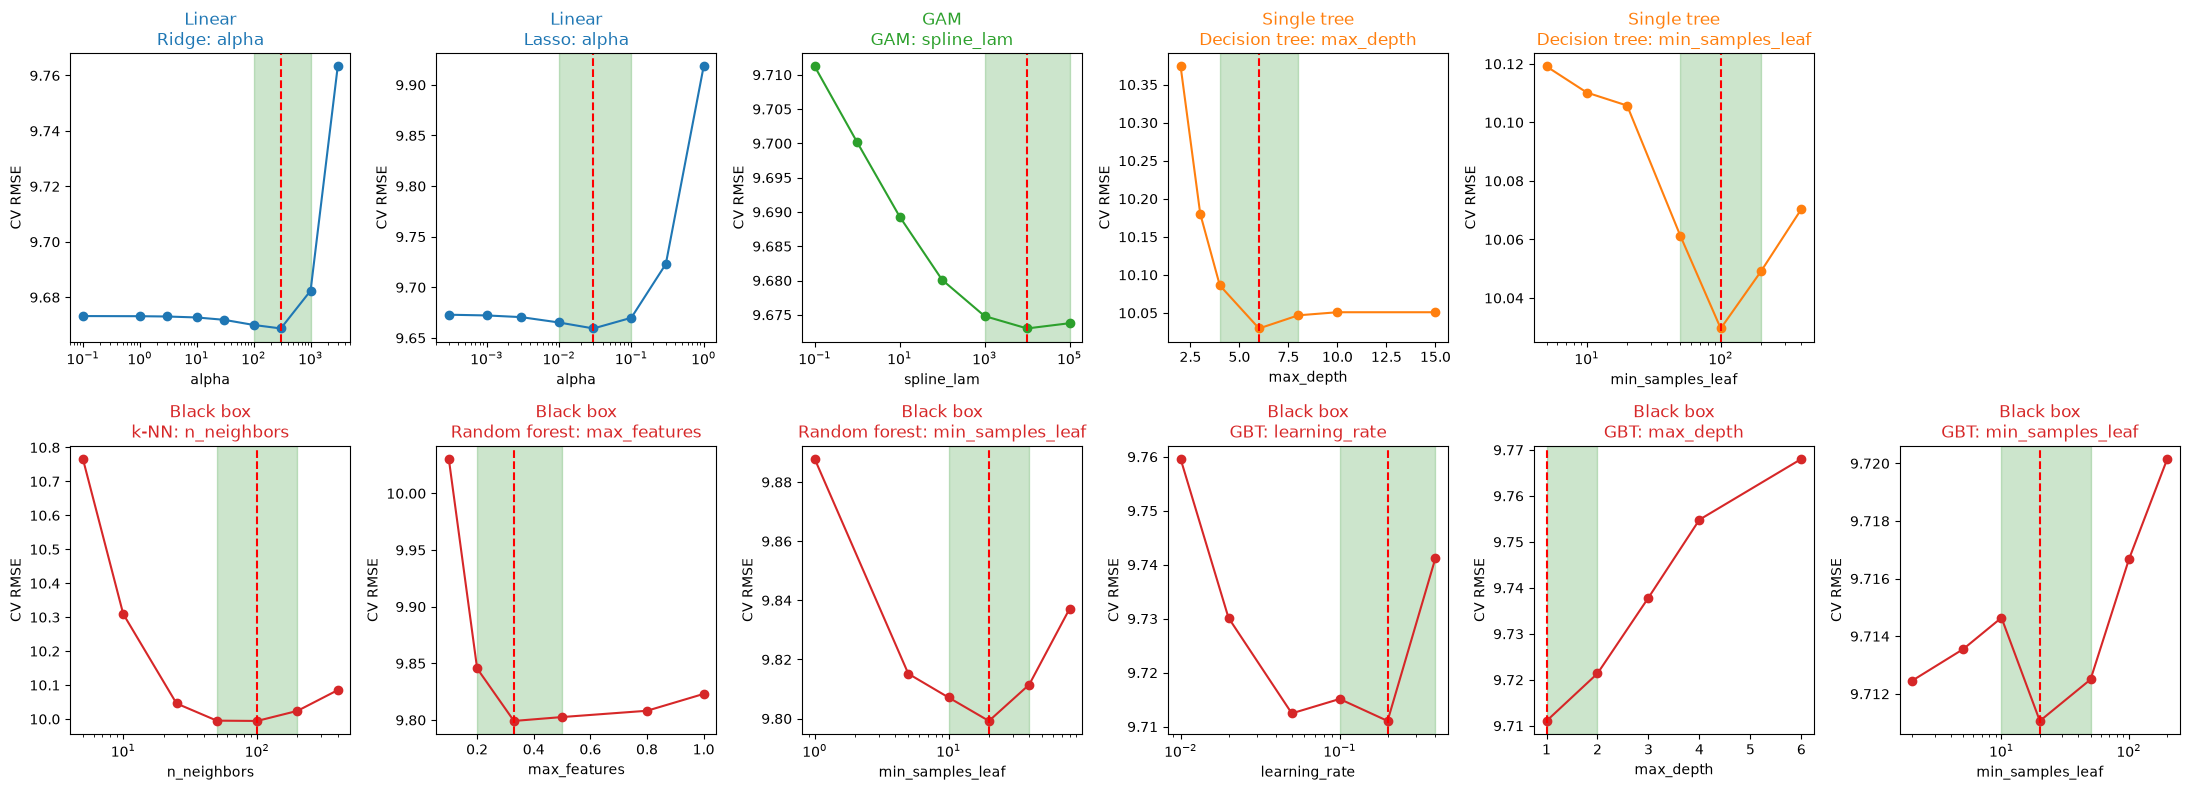

In [63]:
# Pilot plots, grouped by model class: red dashed line = best value, green band = values passed on to the main experiment
# Colours are the same as in the regression comparison plots
colours = {'Linear': 'tab:blue', 'GAM': 'tab:green', 'Single tree': 'tab:orange', 'Black box': 'tab:red'}

# (model class, model, hyperparameter). Top row = interpretable models, bottom row = black boxes
# k-NN weights (uniform or distance) is not a number, so it is not plotted
top_row    = [('Linear', 'Ridge', 'alpha'), ('Linear', 'Lasso', 'alpha'), ('GAM', 'GAM', 'spline_lam'),
              ('Single tree', 'Decision tree', 'max_depth'), ('Single tree', 'Decision tree', 'min_samples_leaf')]
bottom_row = [('Black box', 'k-NN', 'n_neighbors'),
              ('Black box', 'Random forest', 'max_features'), ('Black box', 'Random forest', 'min_samples_leaf'),
              ('Black box', 'GBT', 'learning_rate'), ('Black box', 'GBT', 'max_depth'), ('Black box', 'GBT', 'min_samples_leaf')]

fig, axes = plt.subplots(2, 6, figsize=(22, 8))

for row, panels in enumerate([top_row, bottom_row]):
    for col, (model_class, name, param) in enumerate(panels):
        ax = axes[row, col]
        full_param = 'model__' + param

        # Best CV RMSE for each value of this hyperparameter (best over the other hyperparameters)
        rmse = -pilot_results[name].groupby('param_' + full_param)['mean_test_score'].max()
        ax.plot(rmse.index.astype(float), rmse.values, marker='o', color=colours[model_class])

        ax.axvspan(min(final_grids[name][full_param]), max(final_grids[name][full_param]), color='green', alpha=0.2)
        ax.axvline(best_values[name][full_param], color='red', linestyle='--')

        # Use a log axis when the tried values cover a wide range
        tried_values = pilot_models[name][1][full_param]
        if max(tried_values) / min(tried_values) > 20:
            ax.set_xscale('log')

        ax.set_title(f'{model_class}\n{name}: {param}', color=colours[model_class])
        ax.set_xlabel(param)
        ax.set_ylabel('CV RMSE')

axes[0, 5].set_visible(False)   # the top row only has 5 plots
plt.tight_layout()
plt.show()

## Stage 2: Regression Experiment 

**Experiment Setup:**

The regression experiment repeats the following steps 20 times for statistical comparison, using a different random 85/15 train-test split each time:

1. Split the train/test data. Every model in a repeat uses the same baseline train/test split, so we can compare models on paired differences.
2. Tune each model's hyperparameters (already based on the narrow range from hyperparameter pilot above) by cross-validation on the 85% training data (5-fold for every model). 
3. Score the tuned model on the 15% test data, which was not used for fitting or tuning.

**Pipeline:**

Imputation, encoding and scaling are all part of each model's pipeline, so they are learned from the training data with no leakage from test set. 

In [38]:
# Main Regression Experiment

import time

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.dummy import DummyRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.inspection import permutation_importance

# One row per (experiment, model): test RMSE, MAE, R2 and CV RMSE (same layout as classification_results)
regression_results = []
regression_names   = ['Naive', 'OLS', 'Ridge', 'Lasso', 'k-NN', 'DT', 'RF', 'GBT', 'GAM']

# Feature importance collected in every experiment, so the feature selection section can report a mean and spread
importance_records        = []   # one row per (experiment, model): permutation importance of every predictor on that experiment's test set
lasso_selection_records   = []   # one row per experiment: True if the Lasso kept the predictor (any encoded column non-zero)
lasso_coefficient_records = []   # one row per experiment: the tuned Lasso's coefficient for every encoded column

def predictor_of(encoded_name):
    # 'onehot__father_occupation_Unemployed' -> 'father_occupation'
    stripped = encoded_name.split('__', 1)[1]
    return max((p for p in PREDICTOR_COLS if stripped == p or stripped.startswith(p + '_')), key=len)


# TEST_SIZE, NUMBER_OF_EXPERIMENTS and INNER_FOLDS come from the experiment settings cell at the start of the Main Experiment.

# HYPERPARAMETERS: come from the pilot cell above (run it first).
ridge_grid         = final_grids['Ridge']
lasso_grid         = final_grids['Lasso']
knn_grid           = final_grids['k-NN']
decision_tree_grid = final_grids['Decision tree']
random_forest_grid = final_grids['Random forest']
gbt_grid           = final_grids['GBT']
gam_grid           = final_grids['GAM']

for experiment in range(NUMBER_OF_EXPERIMENTS):

    # Step 1. 85/15 train/test split: standardized baseline for model comparison across models for this experiment
    X_train, X_test, Y_train, Y_test = train_test_split(X, Y_regression, test_size=TEST_SIZE, random_state=experiment, shuffle=True)
    experiment_start_time = time.time()
    print('train:', X_train.shape, ' test:', X_test.shape)

    # Step 2. Model-specific pre-processing (one-hot/ordinal encoding, standardization etc.)
    # Each pipeline chains a preprocessor with a final model, so it can be fitted and used to predict directly
    naive_pipe               = Pipeline([('prep', make_linear_prep()), ('model', DummyRegressor(strategy='mean'))])                                                                                          # Baseline: training mean
    ols_pipe                 = Pipeline([('prep', make_linear_prep()), ('model', LinearRegression())])                                                                                                               # Linear: OLS
    ridge_pipe               = Pipeline([('prep', make_linear_prep()), ('model', Ridge())])                                                                                                                  # Linear: Ridge
    lasso_pipe               = Pipeline([('prep', make_linear_prep()), ('model', Lasso(max_iter=10000))])                                                                                                    # Linear: Lasso
    k_nearest_neighbors_pipe = Pipeline([('prep', make_knn_prep()),    ('model', KNeighborsRegressor())])                                                                                                            # k-NN
    decision_tree_pipe       = Pipeline([('prep', make_tree_prep()),   ('model', DecisionTreeRegressor(random_state=experiment))])                                                                           # Decision tree
    random_forest_pipe       = Pipeline([('prep', make_tree_prep()),   ('model', RandomForestRegressor(n_estimators=100, random_state=experiment))])                                                        # Random forest
    gradient_boosting_pipe   = Pipeline([('prep', make_gbt_prep()),    ('model', GradientBoostingRegressor(n_estimators=500, n_iter_no_change=10, random_state=experiment))])                                  # Boosting / GBT
    gam_pipe                 = Pipeline([('prep', make_gam_prep()),    ('model', GAMRegressor())])

    # Step 3. GridSearchCV - K-folds on 85% training data with aim of finding the best hyperparameters.
    cv = KFold(n_splits=INNER_FOLDS, shuffle=True, random_state=experiment)
    scoring = 'neg_root_mean_squared_error'

    # Define the grid searches
    ridge_search                = GridSearchCV(ridge_pipe,               ridge_grid,         cv=cv, scoring=scoring, n_jobs=-1)
    lasso_search                = GridSearchCV(lasso_pipe,               lasso_grid,         cv=cv, scoring=scoring, n_jobs=-1)
    k_nearest_neighbors_search  = GridSearchCV(k_nearest_neighbors_pipe, knn_grid,           cv=cv, scoring=scoring, n_jobs=-1)
    decision_tree_search        = GridSearchCV(decision_tree_pipe,       decision_tree_grid, cv=cv, scoring=scoring, n_jobs=-1)
    random_forest_search        = GridSearchCV(random_forest_pipe,       random_forest_grid, cv=cv, scoring=scoring, n_jobs=-1)
    gradient_boosting_search    = GridSearchCV(gradient_boosting_pipe,   gbt_grid,           cv=cv, scoring=scoring, n_jobs=-1)
    gam_search                  = GridSearchCV(gam_pipe,                 gam_grid,           cv=cv, scoring=scoring, n_jobs=1)

    # Steps 4 and 5. Fit each model on the training data and score it on the test data
    # GridSearchCV objects predict with their best refitted pipeline.
    fitted_models = [
        ('Naive', naive_pipe),
        ('OLS',   ols_pipe),
        ('Ridge', ridge_search),
        ('Lasso', lasso_search),
        ('k-NN',  k_nearest_neighbors_search),
        ('DT',    decision_tree_search),
        ('RF',    random_forest_search),
        ('GBT',   gradient_boosting_search),
        ('GAM',   gam_search)
    ]

    for name, model in fitted_models:
        model.fit(X_train, Y_train)
        test_rmse, test_mae, test_r2, cv_rmse = compute_test_metrics(model, X_train, Y_train, X_test, Y_test, cv)
        regression_results.append({
            'experiment': experiment + 1, 'model': name, 'CV RMSE': cv_rmse,
            'RMSE': test_rmse, 'MAE': test_mae, 'R2': test_r2,
            'best parameters': getattr(model, 'best_params_', {}),    # Naive and OLS have no hyperparameters
        })

    # Step 5b. Feature importance of the tuned models on this experiment's test set
    # (family_income_bracket is in X only for the imputer, so it is left out of the records)
    for importance_name, importance_search in [('Lasso', lasso_search), 
                                               ('DT', decision_tree_search),
                                               ('RF', random_forest_search), 
                                               ('GBT', gradient_boosting_search), 
                                               ('GAM', gam_search)]:
        result = permutation_importance(importance_search.best_estimator_, X_test, Y_test,
                                        scoring='neg_root_mean_squared_error', n_repeats=5, random_state=experiment)
        importance_records.append({'experiment': experiment, 'model': importance_name,
                                   **{col: value for col, value in zip(X_test.columns, result.importances_mean) if col in PREDICTOR_COLS}})

    # Predictors the tuned Lasso kept in this experiment
    lasso_best = lasso_search.best_estimator_
    lasso_coefficients = pd.Series(lasso_best.named_steps['model'].coef_, index=lasso_best.named_steps['prep'].get_feature_names_out())
    kept_predictors = {predictor_of(name) for name in lasso_coefficients.index[lasso_coefficients != 0]}
    lasso_selection_records.append({'experiment': experiment, **{p: p in kept_predictors for p in PREDICTOR_COLS}})
    lasso_coefficient_records.append({'experiment': experiment, **lasso_coefficients.to_dict()})

    print(f'experiment {experiment + 1}/{NUMBER_OF_EXPERIMENTS} done in {time.time() - experiment_start_time:.0f}s')

# One table of results: one row per model per experiment
regression_results = pd.DataFrame(regression_results)

train: (10200, 22)  test: (1800, 22)
experiment 1/3 done in 39s
train: (10200, 22)  test: (1800, 22)
experiment 2/3 done in 39s
train: (10200, 22)  test: (1800, 22)
experiment 3/3 done in 39s


## Model Performance Metrics

We use **test RMSE** as the main metric. It is in grade points, so it is easy to read, and it is also what we tuned on.

Alongside it we report:

- **R2**: share of the variation in final grades that the model explains (the naive model is about 0).
- **MAE**: average absolute error. It is less affected by a few large errors, so if RMSE is much bigger than MAE, some students are being predicted very badly.
- **CV RMSE**: the RMSE from tuning on the 85% training data. We only use it as a check: if it is close to the test RMSE, the tuning was not over-optimistic.

## Regression Performance Analysis: Summary table and box plot

The box plot shows the spread of test RMSE over the 20 splits. Most of that spread comes from some test splits being harder than others for every model, so small differences between models are easier to see in the paired comparison further down.

       RMSE mean  RMSE SD  R2 mean  MAE mean  CV RMSE mean
model                                                     
Naive     11.728    0.233   -0.000     9.081        11.690
OLS        9.645    0.228    0.324     7.189         9.642
Ridge      9.641    0.234    0.324     7.190         9.636
Lasso      9.636    0.234    0.325     7.186         9.629
k-NN       9.969    0.241    0.277     7.517         9.963
DT        10.004    0.223    0.272     7.507        10.007
RF         9.787    0.253    0.303     7.313         9.771
GBT        9.698    0.252    0.316     7.225         9.681
GAM        9.663    0.228    0.321     7.197         9.645

Largest gap between CV RMSE and test RMSE: 0.038


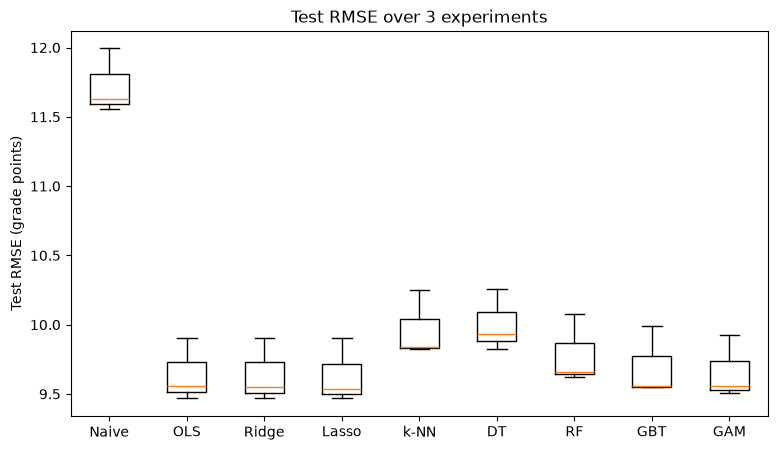

In [39]:
# One row per experiment, one column per model (every model was scored on the same splits)
regression_scores = regression_results.pivot(index='experiment', columns='model', values='RMSE')[regression_names]

# Mean (and SD for RMSE) over the 20 experiments
by_model = regression_results.groupby('model')
regression_summary = pd.DataFrame({
    'RMSE mean':    by_model['RMSE'].mean(),
    'RMSE SD':      by_model['RMSE'].std(),
    'R2 mean':      by_model['R2'].mean(),
    'MAE mean':     by_model['MAE'].mean(),
    'CV RMSE mean': by_model['CV RMSE'].mean(),
}).reindex(regression_names)
print(regression_summary.round(3))

# Check that tuning was not over-optimistic: CV RMSE (training data) vs test RMSE
gap = (regression_summary['CV RMSE mean'] - regression_summary['RMSE mean']).abs()
print('\nLargest gap between CV RMSE and test RMSE:', round(gap.max(), 3))

# Box plot of test RMSE over the 20 experiments
plt.figure(figsize=(9, 5))
plt.boxplot([regression_scores[name] for name in regression_names])
plt.xticks(range(1, len(regression_names) + 1), regression_names)
plt.ylabel('Test RMSE (grade points)')
plt.title(f'Test RMSE over {len(regression_scores)} experiments')
plt.show()

### Regression Performance Analysis: Paired t-tests

We want to know if the best model (the one with the lowest mean test RMSE) is really better than each of the other models, or if the difference could just be noise from the random train/test splits.

Every model uses the same 20 train/test splits, so we compare two models split by split with a paired t-test (`ttest_rel`), as in the labs.

As in the labs, we use the p-values only as a sanity check, not as formal proof:

- The 20 splits are not independent. They all reuse the same 12,000 students, so the test is too confident and the p-values come out smaller than they should be.
- We picked the best model using the same test results, and we did not adjust for making eight comparisons.

So we also look at the size of each difference. A difference of a few hundredths of a grade point is not meaningful in practice, even if its p-value is small.

The plot shows each model's RMSE minus the best model's RMSE, averaged over the 20 splits, with error bars of 2 standard errors. Naive is left out of the plot because it is far off the scale (see the summary table).

Best model on RMSE: Lasso


,RMSE mean,RMSE SD,diff mean,diff SD,p-value,significant
model,,,,,,
Naive,11.728,0.233,2.092,0.002,0.0000,yes
OLS,9.645,0.228,0.009,0.009,0.2228,no
Ridge,9.641,0.234,0.006,0.006,0.2431,no
Lasso,9.636,0.234,,,,best model
k-NN,9.969,0.241,0.333,0.042,0.0054,yes
DT,10.004,0.223,0.368,0.087,0.0182,yes
RF,9.787,0.253,0.152,0.058,0.0461,yes
GBT,9.698,0.252,0.062,0.036,0.0945,no
GAM,9.663,0.228,0.028,0.011,0.0528,no


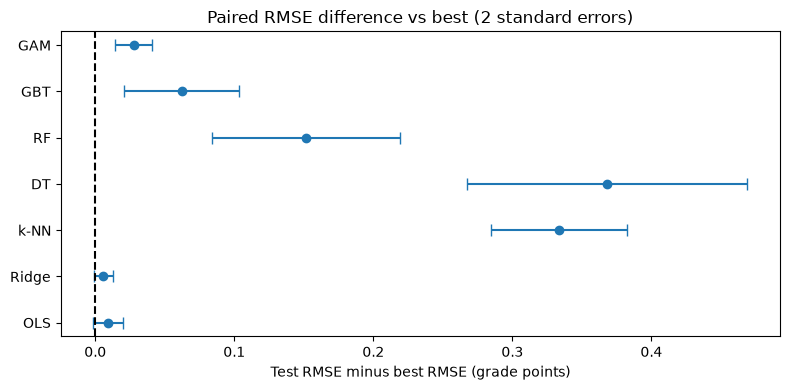

In [42]:
from scipy.stats import ttest_rel

# Paired t-test: is the best model really better than each of the others?
# The splits reuse the same students, so the p-values are too small: we only use them as a sanity check
rmse = {name: regression_scores[name].values for name in regression_names}
best = min(rmse, key=lambda name: rmse[name].mean())
print("Best model on RMSE:", best)

# Significant = p < 0.05
ttest_rows = {}
for name in rmse:
    row = {"RMSE mean": rmse[name].mean(), "RMSE SD": rmse[name].std(ddof=1)}
    if name == best:
        row.update({"diff mean": np.nan, "diff SD": np.nan, "p-value": np.nan, "significant": "best model"})
    else:
        diff = rmse[name] - rmse[best]
        p = ttest_rel(rmse[name], rmse[best]).pvalue
        row.update({
            "diff mean": diff.mean(),
            "diff SD": diff.std(ddof=1),
            "p-value": p,
            "significant": "yes" if p < 0.05 else "no",
        })
    ttest_rows[name] = row

ttest_table = pd.DataFrame(ttest_rows).T
ttest_table.index.name = "model"
display(
    ttest_table.style.format(
        {
            "RMSE mean": "{:.3f}",
            "RMSE SD": "{:.3f}",
            "diff mean": "{:.3f}",
            "diff SD": "{:.3f}",
            "p-value": "{:.4f}",
        },
        na_rep="",
    )
)

# Paired differences against the best model, with error bars of 2 standard errors
others = [name for name in regression_names if name not in (best, "Naive")]  # Naive is far off the scale, see the table
n = len(regression_scores)
mean_diffs = [(rmse[name] - rmse[best]).mean() for name in others]
margins = [
    2 * (rmse[name] - rmse[best]).std(ddof=1) / np.sqrt(n)
    for name in others
]

plt.figure(figsize=(8, 4))
plt.errorbar(
    mean_diffs,
    range(len(others)),
    xerr=margins,
    fmt="o",
    capsize=4,
)
plt.yticks(range(len(others)), others)
plt.axvline(0, color="black", linestyle="--")
plt.xlabel("Test RMSE minus best RMSE (grade points)")
plt.title("Paired RMSE difference vs best (2 standard errors)")
plt.tight_layout()
plt.show()

### Regression Performance Analysis: Actual vs. predicted grades

Test predictions from the **final repeat** for the best linear model (Lasso) and the best black box model (GBT). The dashed line is a perfect prediction and the red dotted line is the at-risk cut-off (final grade below 40).

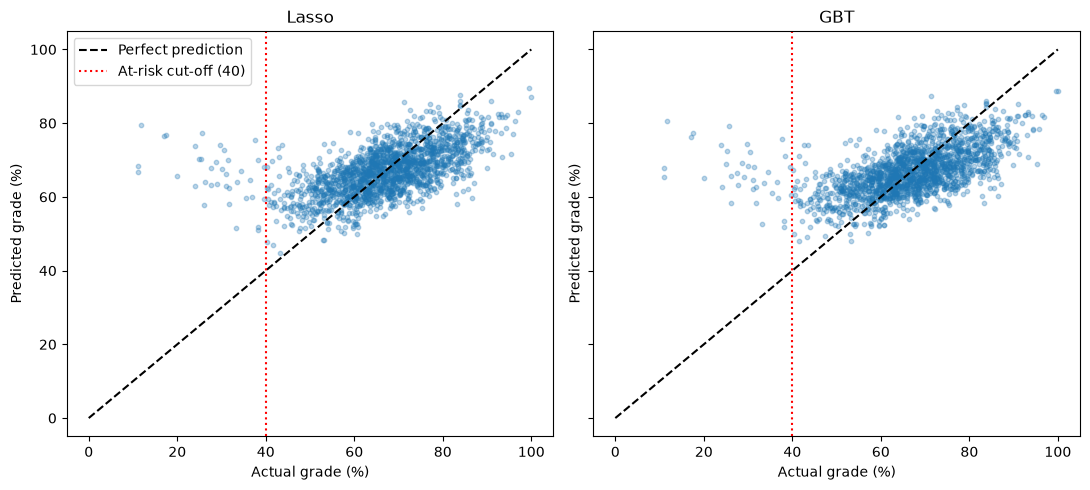

In [43]:
# Actual vs predicted grades on the final repeat's test set (no refitting)
plot_models = {'Lasso': lasso_search, 'GBT': gradient_boosting_search}

fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
for ax, (name, model) in zip(axes, plot_models.items()):
    ax.scatter(Y_test, model.predict(X_test), s=10, alpha=0.3)
    ax.plot([0, 100], [0, 100], color='black', linestyle='--', label='Perfect prediction')
    ax.axvline(40, color='red', linestyle=':', label='At-risk cut-off (40)')
    ax.set_title(name)
    ax.set_xlabel('Actual grade (%)')
    ax.set_ylabel('Predicted grade (%)')
axes[0].legend()
plt.tight_layout()
plt.show()

### Regression Performance Analysis: Shape of the effects (GAM)

The GAM fits a smooth curve for each continuous predictor, so its partial dependence plots show whether the effects bend or are straight lines. Each plot is one predictor’s effect on the predicted grade with the other predictors held fixed, with a 95% confidence band. If the curves are close to straight lines, a linear model can capture them, which helps explain the results above.

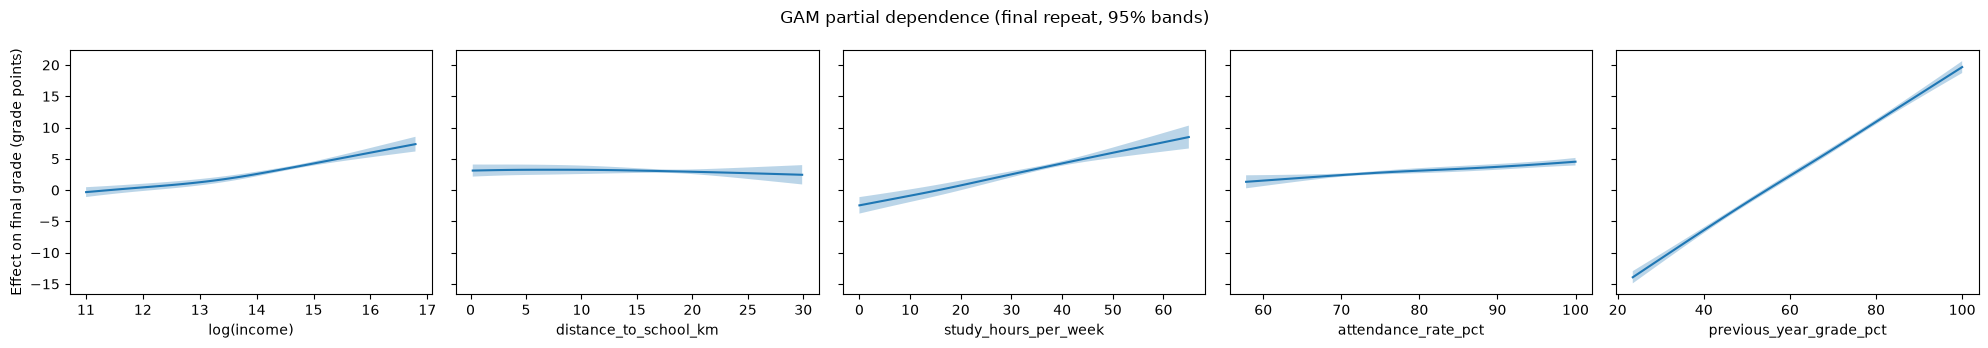

In [44]:
# Partial dependence of the GAM's five spline terms, from the tuned GAM of the final repeat (no refitting)
gam_model = gam_search.best_estimator_.named_steps["model"]
spline_cols = [col for col in gam_model.columns_ if col in CONTINUOUS_COLS]

fig, axes = plt.subplots(
    1,
    len(spline_cols),
    figsize=(4 * len(spline_cols), 3.5),
    sharey=True,
)

for ax, col in zip(axes, spline_cols):
    i = gam_model.columns_.index(col)
    grid = gam_model.gam_.generate_X_grid(term=i)
    effect, band = gam_model.gam_.partial_dependence(
        term=i,
        X=grid,
        width=0.95,
    )
    ax.plot(grid[:, i], effect)
    ax.fill_between(grid[:, i], band[:, 0], band[:, 1], alpha=0.3)
    ax.set_xlabel("log(income)" if col == "annual_family_income_inr" else col)

axes[0].set_ylabel("Effect on final grade (grade points)")
fig.suptitle("GAM partial dependence (final repeat, 95% bands)")
plt.tight_layout()
plt.show()

**Analysing the plots**: All 5 effects are close to straight lines within their bands. Previous grade rises steadily (about 33 grade points from the lowest to the highest previous grade); study hours and income rise more gently (income bends upward slightly at the top); attendance has a small upward slope; and distance is flat. The GAM was free to fit curves but found almost none, which is why it scores about the same as the linear models rather than better.

### Regression Performance Analysis: Baseline vs Predictive Models

**Question: how much signal is there at all?** The Naive model predicts every student's grade as the training average, so it shows how well we can do with no predictors at all. Every other model is compared with it.

- Every model beats Naive on all 20 splits. The Lasso cuts the test RMSE from 11.702 to 9.685 grade points, about 2.0 points or 17% better, and even the weakest model, the decision tree, is 1.7 points better than Naive.
- But the signal is limited. The best models explain only about 31% of the variation in final grades (R² = 0.315 for the Lasso), so about 69% is left unexplained. Limitation 2 shows that a large part of this comes from a small group of students with sudden, unpredictable drops.
- The models are much closer to each other than to Naive: all of them are within 0.35 grade points of the Lasso, while Naive is 2.0 points behind. Most of the available gain comes from using the predictors at all, not from the choice of model.
- **Price to pay:** none. Moving from the Naive guess to any model is clearly worth it.

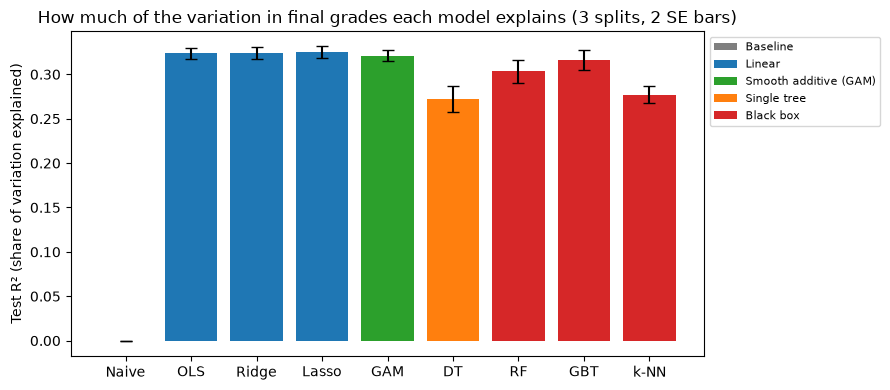

Lasso vs Naive: test RMSE 11.728 -> 9.636, 2.09 grade points better (18%), better on 3 of 3 splits
Lasso explains 32% of the variation in final grades, so 68% is left unexplained


In [45]:
# How much signal is there at all? Share of the variation in final grades each model explains (test R2)
# Colour = model class, used again in the next two plots
model_class = {
    'Naive': 'Baseline',
    'OLS': 'Linear', 'Ridge': 'Linear', 'Lasso': 'Linear',
    'GAM': 'Smooth additive (GAM)',
    'DT': 'Single tree',
    'RF': 'Black box', 'GBT': 'Black box', 'k-NN': 'Black box',
}
class_colours = {'Baseline': 'tab:gray', 'Linear': 'tab:blue', 'Smooth additive (GAM)': 'tab:green',
                 'Single tree': 'tab:orange', 'Black box': 'tab:red'}
plot_order = ['Naive', 'OLS', 'Ridge', 'Lasso', 'GAM', 'DT', 'RF', 'GBT', 'k-NN']

r2_scores = regression_results.pivot(index='experiment', columns='model', values='R2')[plot_order]
n = len(r2_scores)

plt.figure(figsize=(9, 4))
plt.bar(plot_order, r2_scores.mean(), yerr=2 * r2_scores.std() / np.sqrt(n), capsize=4,
        color=[class_colours[model_class[name]] for name in plot_order])
for label, colour in class_colours.items():
    plt.bar(0, 0, color=colour, label=label)    # empty bars, only used for the legend
plt.ylabel('Test R² (share of variation explained)')
plt.title(f'How much of the variation in final grades each model explains ({n} splits, 2 SE bars)')
plt.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1, 1))    # legend outside the plot, so it does not cover the bars
plt.tight_layout()
plt.show()

gain = regression_scores['Naive'] - regression_scores['Lasso']
print(f"Lasso vs Naive: test RMSE {regression_scores['Naive'].mean():.3f} -> {regression_scores['Lasso'].mean():.3f}, "
      f"{gain.mean():.2f} grade points better ({100 * gain.mean() / regression_scores['Naive'].mean():.0f}%), better on {(gain > 0).sum()} of {n} splits")
print(f"Lasso explains {r2_scores['Lasso'].mean():.0%} of the variation in final grades, so {1 - r2_scores['Lasso'].mean():.0%} is left unexplained")

### Regression Performance Analysis: Linear vs Nonlinear Models Performance

**Question: does a GAM or boosting beat the linear models?** If models that can fit curves (GAM) or curves and interactions (GBT, random forest, k-NN) do not beat the Lasso, the signal is probably mostly linear.

| Model | What it can fit beyond straight lines | Test RMSE minus Lasso | Splits where it beat the Lasso |
|---|---|---|---|
| GAM | curved effects | +0.014 | 2 of 20 |
| GBT | curves and interactions | +0.049 | 0 of 20 |
| Random forest | curves and interactions | +0.130 | 0 of 20 |
| k-NN | any shape | +0.312 | 0 of 20 |

- No nonlinear model beats the Lasso. The GAM comes closest, but it is still slightly worse on 18 of the 20 splits.
- The models' own tuning points the same way. The GAM chose the strongest smoothing on offer (λ = 100,000) in 13 of the 20 splits, which pushes its curves towards straight lines, and its partial dependence plots above are almost straight. GBT chose trees of depth 1 (stumps) in all 20 splits. A boosted sum of stumps can only add up a separate effect for each predictor (Week 9: boosted stumps are a GAM), so cross-validation never found an interaction worth fitting.
- The differences are significant in the paired t-test (p < 0.001) because they are very consistent across splits, but they are small: 0.014 grade points for the GAM and 0.05 for GBT.
- **Answer:** the signal is essentially linear and additive. **Price to pay:** switching from the Lasso to a nonlinear model costs a little accuracy and gains nothing, so it is not worth it.

GAM   mean diff = +0.028 grade points   beats the Lasso on 0 of 3 splits
GBT   mean diff = +0.062 grade points   beats the Lasso on 0 of 3 splits
RF    mean diff = +0.152 grade points   beats the Lasso on 0 of 3 splits
k-NN  mean diff = +0.333 grade points   beats the Lasso on 0 of 3 splits


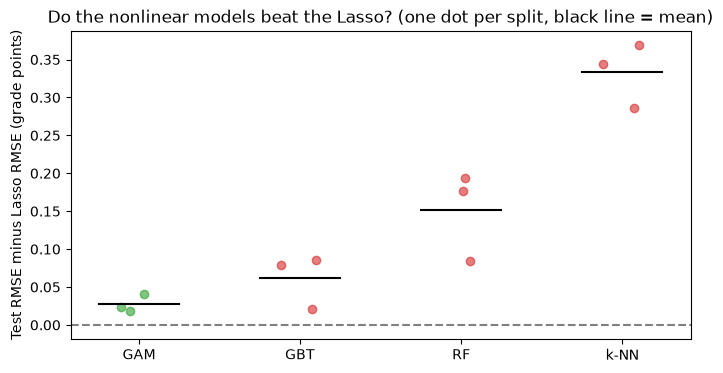


GBT max_depth chosen: {1: 3}
GAM spline_lam chosen: {10000: 2, 100000: 1}


In [46]:
# Linear vs nonlinear: each nonlinear model's test RMSE minus the Lasso's, split by split (below 0 = beats the Lasso)
nonlinear = ['GAM', 'GBT', 'RF', 'k-NN']
rng = np.random.default_rng(0)     # small sideways jitter so the dots do not sit on top of each other

plt.figure(figsize=(8, 4))
for i, name in enumerate(nonlinear):
    diff = regression_scores[name] - regression_scores['Lasso']
    plt.scatter(i + rng.uniform(-0.12, 0.12, len(diff)), diff, alpha=0.6, color=class_colours[model_class[name]])
    plt.plot([i - 0.25, i + 0.25], [diff.mean(), diff.mean()], color='black')
    print(f'{name:5} mean diff = {diff.mean():+.3f} grade points   beats the Lasso on {(diff < 0).sum()} of {len(diff)} splits')
plt.axhline(0, color='grey', linestyle='--')
plt.xticks(range(len(nonlinear)), nonlinear)
plt.ylabel('Test RMSE minus Lasso RMSE (grade points)')
plt.title('Do the nonlinear models beat the Lasso? (one dot per split, black line = mean)')
plt.show()

# What the tuning chose: GBT tree depth (1 = no interactions) and GAM smoothing (higher = straighter curves)
best_params = regression_results.set_index('model')['best parameters']
print('\nGBT max_depth chosen:', pd.Series([p['model__max_depth'] for p in best_params['GBT']]).value_counts().to_dict())
print('GAM spline_lam chosen:', pd.Series([p['model__spline_lam'] for p in best_params['GAM']]).value_counts().to_dict())

### Regression Performance Analysis: Price of Interpretability (Interpretable vs Black Box)

**Question: what do we gain or lose by giving up transparency?** We compare each interpretable model with the black boxes, split by split. A negative change means the black box is more accurate.

| Switch | Change in test RMSE | Black box better on | Worth it? |
|---|---|---|---|
| **Lasso → GBT (headline)** | +0.049 (+0.5%) | 0 of 20 splits | No: less accurate and harder to explain |
| Lasso → random forest | +0.130 (+1.3%) | 0 of 20 splits | No |
| Decision tree → GBT | −0.296 (−3.0%) | 20 of 20 splits | Yes, if the choice is between these two |
| Decision tree → random forest | −0.215 (−2.1%) | 20 of 20 splits | Yes, if the choice is between these two |

- **Interpretable tree vs black box:** a single decision tree is easy to read, but it is the least accurate model. Combining many trees (random forest, GBT) recovers 0.2–0.3 grade points, so against a single tree the black box does pay for its lost transparency.
- **Interpretable linear vs gradient boosting (headline):** the Lasso is more accurate than GBT on every one of the 20 splits. **The black box was not worth it:** it costs accuracy as well as transparency. The Lasso gives one coefficient per predictor that can be read directly (Stage 4), and the GAM gives the shape of each effect at almost no cost (+0.014).
- **Recommendation:** use the Lasso, or OLS, which is within 0.01 grade points and needs no tuning. Use the GAM if the shape of each effect matters.

Lasso -> GBT: change = +0.062 grade points (+0.6%), black box better on 0 of 3 splits, p = 0.095
Lasso -> RF : change = +0.152 grade points (+1.6%), black box better on 0 of 3 splits, p = 0.046
DT    -> GBT: change = -0.306 grade points (-3.1%), black box better on 3 of 3 splits, p = 0.015
DT    -> RF : change = -0.217 grade points (-2.2%), black box better on 3 of 3 splits, p = 0.016


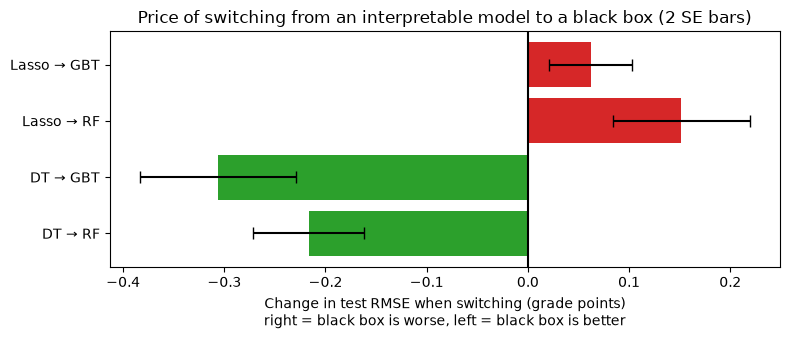

In [47]:
from scipy.stats import ttest_rel

# Price of interpretability: change in test RMSE when switching from an interpretable model to a black box
# (paired over the 20 splits; below 0 = the black box is more accurate)
switches = [('Lasso', 'GBT'), ('Lasso', 'RF'), ('DT', 'GBT'), ('DT', 'RF')]
labels, changes, margins = [], [], []
for start, end in switches:
    change = regression_scores[end] - regression_scores[start]
    p = ttest_rel(regression_scores[end], regression_scores[start]).pvalue
    labels.append(f'{start} → {end}')
    changes.append(change.mean())
    margins.append(2 * change.std() / np.sqrt(len(change)))
    print(f'{start:5} -> {end:3}: change = {change.mean():+.3f} grade points ({100 * change.mean() / regression_scores[start].mean():+.1f}%), '
          f'black box better on {(change < 0).sum()} of {len(change)} splits, p = {p:.2g}')

plt.figure(figsize=(8, 3.5))
plt.barh(labels, changes, xerr=margins, capsize=4, color=['tab:red' if c > 0 else 'tab:green' for c in changes])
plt.axvline(0, color='black')
plt.gca().invert_yaxis()
plt.xlabel('Change in test RMSE when switching (grade points)\nright = black box is worse, left = black box is better')
plt.title('Price of switching from an interpretable model to a black box (2 SE bars)')
plt.tight_layout()
plt.show()

### Regression Performance Analysis: Conclusion

- **Signal:** every model beats the Naive baseline by about 2 grade points, but the best models explain only about 31% of the variation in final grades.
- **Linear vs nonlinear:** no nonlinear model beats the Lasso. The GAM finds nearly straight effects and GBT never uses interactions, so the signal is linear and additive.
- **Interpretable vs black box:** the black boxes only beat the single decision tree. Against the Lasso they lose on every split, so interpretability costs nothing here and the black box was not worth it.

**How far can we rely on this?** The p-values are only a sanity check: the splits reuse the same students, the best model was chosen on the same results, and the eight comparisons are not adjusted. So we read the size of each difference, not just its p-value. The gaps between the linear models, the GAM and GBT are a few hundredths of a grade point, so in practice these models perform about the same, and the conclusion is that the extra flexibility buys nothing. Linear models matching flexible ones is also unusual on real tabular data and may reflect how this dataset was built (see Limitation 2), so we do not claim the same would hold for other student populations.

## Stage 3: Classification Experiment

**Motivation**
The predicted vs. actual grade plots show particularly poor regression performance for F-grade students (final grade below 40). Many of the largest prediction errors occur among students with low actual grades. If our goal is to identify students at risk of failing so that they can receive support, we can approach this as a classification problem, predicting `at_risk_flag` directly.


**How the experiment is setup**

The classification experiment predicts `at_risk_flag` (1 = final grade below 40) from the same predictors as the regression experiment. It uses 5-fold stratified cross-validation repeated 4 times, which gives 20 train/test splits (80/20) for statistical comparison:

1. Split the train/test data, stratified by `at_risk_flag` so that the rare at-risk students (218 of 12,000, about 1.8%) appear in every split in the same proportion. We use K-fold instead of random splits because there are so few at-risk students: each test set has about 44 of them, and every at-risk student is in a test set once per repeat. Every model uses the same splits, so we can compare models on paired differences.
2. Tune each model's hyperparameters by 5-fold stratified cross-validation on the 80% training data only, choosing the settings with the best AUC. We did not run a separate pilot for classification. Each model is tuned over a small grid of the settings that matter most for it, for example C and gamma for the RBF SVM, depth and leaf size for the decision tree, and learning rate, depth and number of trees for GBT. The random forest grid includes using all predictors at every split (`max_features = 1.0`), which is bagging, so cross-validation decides between bagging and a random forest.
3. Score the tuned model on the 20% test data, which was not used for fitting or tuning.

Imputation, encoding and scaling are all part of each model's pipeline, so they are also learned from the training data only.

In [48]:
# Main Classification Experiment (target: at_risk_flag)
import time
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier


# One row per (experiment, model): test AUC and CV AUC
classification_results = []
classification_names   = ['Naive', 'Logistic', 'Logistic L1', 'DT', 'RF', 'GBT', 'k-NN', 'SVM']

# HYPERPARAMETERS: small grids over the settings that matter most for each model (no separate pilot for classification)
logistic_l1_class_grid         = {'model__C':                           [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0, 100.0]}
decision_tree_class_grid       = {'model__max_depth':                   [3, 5, 8],
                                  'model__min_samples_leaf':            [10, 30, 100, 200]}
random_forest_class_grid       = {'model__max_features':                ['sqrt', 0.33, 1.0],    # 1.0 = all predictors at every split, which is bagging
                                  'model__min_samples_leaf':            [10, 50, 100]}
gradient_boosting_class_grid   = {'model__learning_rate':               [0.05, 0.1],
                                  'model__max_depth':                   [1, 2, 3],
                                  'model__n_estimators':                [100, 300]}
k_nearest_neighbors_class_grid = {'model__n_neighbors':                 [50, 100, 200],
                                  'model__weights':                     ['uniform', 'distance']}
svm_class_grid                 = {'model__C':                           [0.1, 1.0, 10.0],
                                  'model__gamma':                       [0.003, 0.01, 0.03, 0.1]}

# Outer splits (outer_cv) and INNER_FOLDS come from the experiment settings cell at the start of the Main Experiment.

for experiment, (train_index, test_index) in enumerate(outer_cv.split(X, Y_classification)):
    # Step 1. Stratified train/test split shared by all classifiers
    X_train_class, X_test_class = X.iloc[train_index], X.iloc[test_index]
    Y_train_class, Y_test_class = Y_classification.iloc[train_index], Y_classification.iloc[test_index]
    experiment_start_time = time.time()

    # Step 2. Set up model-specific preprocessing and classifiers
    naive_class_pipe               = Pipeline([('prep', make_tree_prep()),   ('model', DummyClassifier(strategy='most_frequent'))])
    logistic_class_pipe            = Pipeline([('prep', make_linear_prep()), ('model', LogisticRegression(C=np.inf, max_iter=5000))])    # no penalty, like OLS in the regression
    logistic_l1_class_pipe         = Pipeline([('prep', make_linear_prep()), ('model', LogisticRegression(l1_ratio=1, solver='saga', max_iter=5000))])
    decision_tree_class_pipe       = Pipeline([('prep', make_tree_prep()),   ('model', DecisionTreeClassifier(random_state=experiment))])
    random_forest_class_pipe       = Pipeline([('prep', make_tree_prep()),   ('model', RandomForestClassifier(n_estimators=300, random_state=experiment, n_jobs=-1))])
    gradient_boosting_class_pipe   = Pipeline([('prep', make_gbt_prep()),    ('model', GradientBoostingClassifier(random_state=experiment))])
    k_nearest_neighbors_class_pipe = Pipeline([('prep', make_knn_prep()),    ('model', KNeighborsClassifier())])
    svm_class_pipe                 = Pipeline([('prep', make_svm_prep()),    ('model', SVC(kernel='rbf'))])

    # Step 3. GridSearchCV - stratified 5-fold CV on the 80% training data to find the best hyperparameters
    cv = StratifiedKFold(n_splits=INNER_FOLDS, shuffle=True, random_state=experiment)
    scoring = 'roc_auc'

    # Define the grid searches (Naive and Logistic have no hyperparameters, they are in a search so that they get the same AUC scoring)
    naive_class_search               = GridSearchCV(naive_class_pipe,               {},                             cv=cv, scoring=scoring)
    logistic_class_search            = GridSearchCV(logistic_class_pipe,            {},                             cv=cv, scoring=scoring)
    logistic_l1_class_search         = GridSearchCV(logistic_l1_class_pipe,         logistic_l1_class_grid,         cv=cv, scoring=scoring)
    decision_tree_class_search       = GridSearchCV(decision_tree_class_pipe,       decision_tree_class_grid,       cv=cv, scoring=scoring, n_jobs=-1)
    random_forest_class_search       = GridSearchCV(random_forest_class_pipe,       random_forest_class_grid,       cv=cv, scoring=scoring)
    gradient_boosting_class_search   = GridSearchCV(gradient_boosting_class_pipe,   gradient_boosting_class_grid,   cv=cv, scoring=scoring, n_jobs=-1)
    k_nearest_neighbors_class_search = GridSearchCV(k_nearest_neighbors_class_pipe, k_nearest_neighbors_class_grid, cv=cv, scoring=scoring, n_jobs=-1)
    svm_class_search                 = GridSearchCV(svm_class_pipe,                 svm_class_grid,                 cv=cv, scoring=scoring, n_jobs=-1)

    # Fit everything on the 80% training data
    naive_class_search.fit(X_train_class, Y_train_class)
    logistic_class_search.fit(X_train_class, Y_train_class)
    logistic_l1_class_search.fit(X_train_class, Y_train_class)
    decision_tree_class_search.fit(X_train_class, Y_train_class)
    random_forest_class_search.fit(X_train_class, Y_train_class)
    gradient_boosting_class_search.fit(X_train_class, Y_train_class)
    k_nearest_neighbors_class_search.fit(X_train_class, Y_train_class)
    svm_class_search.fit(X_train_class, Y_train_class)

    # Step 4. Evaluate each model's best hyperparameters on the 20% test data
    # GridSearchCV objects predict with their best refitted pipeline
    fitted_class_models = [
        ('Naive',       naive_class_search),
        ('Logistic',    logistic_class_search),
        ('Logistic L1', logistic_l1_class_search),
        ('DT',          decision_tree_class_search),
        ('RF',          random_forest_class_search),
        ('GBT',         gradient_boosting_class_search),
        ('k-NN',        k_nearest_neighbors_class_search),
        ('SVM',         svm_class_search)
    ]

    # Step 5. Record AUC for this iteration
    for name, search in fitted_class_models:
        test_auc, cv_auc = compute_classification_test_metrics(search, X_test_class, Y_test_class)
        classification_results.append({
            'experiment': experiment + 1, 'model': name, 'CV AUC': cv_auc,
            'AUC': test_auc,
            'best parameters': search.best_params_,
        })
    print(f'experiment {experiment + 1}/{NUMBER_OF_CLASS_EXPERIMENTS} done in {time.time() - experiment_start_time:.0f}s')

# One table of results: one row per model per experiment
classification_results = pd.DataFrame(classification_results)
classification_summary = classification_results.groupby('model')[['CV AUC', 'AUC']].agg(['mean', 'std']).reindex(classification_names)

experiment 1/5 done in 228s
experiment 2/5 done in 228s
experiment 3/5 done in 193s
experiment 4/5 done in 151s
experiment 5/5 done in 129s


## Model Performance Metrics

We use AUC for all eight classification models:

- **AUC**: the chance that a randomly chosen at-risk student gets a higher predicted risk than a randomly chosen student who is not at risk. It uses the predicted probabilities (decision scores for the SVM), so it measures how well a model ranks students instead of depending on hard labels. The naive model scores 0.50
- **CV AUC**: AUC from the 5-fold tuning on the 80% training data (`best_score_`). Compared with the test AUC, it shows how well tuning predicts test performance

We focus on AUC because only about 1.8% of students are at risk. Accuracy is not useful here, as a naive model that always predicts "not at risk" already scores about 0.98.

## Classification Performance Analysis

Box plot of each model's test AUC over the 20 splits. The dashed line at 0.5 is guessing (the Naive model always scores 0.5), so a box close to it means the model ranks at-risk students little better than chance.

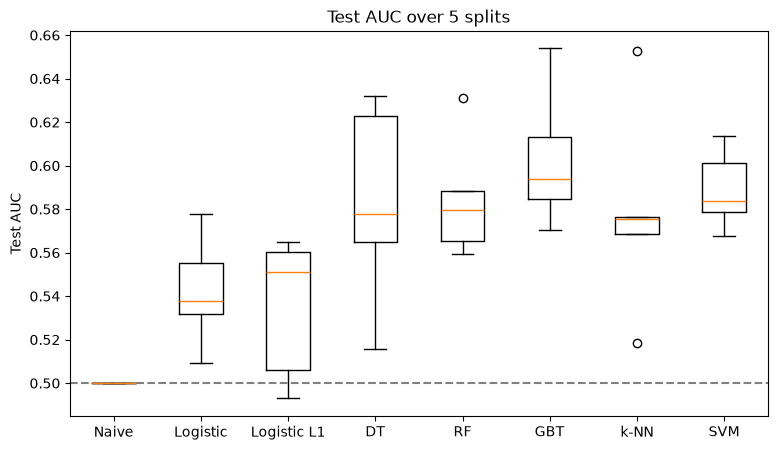

In [49]:
# One row per split, one column per model (every model was scored on the same splits)
classification_scores = classification_results.pivot(index='experiment', columns='model', values='AUC')[classification_names]

# Box plot of test AUC over the 20 splits (dashed line = guessing, AUC 0.5)
plt.figure(figsize=(9, 5))
plt.boxplot([classification_scores[name] for name in classification_names])
plt.xticks(range(1, len(classification_names) + 1), classification_names)
plt.axhline(0.5, color='grey', linestyle='--')
plt.ylabel('Test AUC')
plt.title(f'Test AUC over {len(classification_scores)} splits')
plt.show()

### Classification Performance Analysis: Paired t-tests

Same idea as the regression t-tests: every model uses the same 20 splits, so we compare the best model (highest mean test AUC) with each of the other models split by split, using a paired t-test (`ttest_rel`) as in the labs.

As in the regression, the p-values are only a sanity check: the splits reuse the same students, so the p-values come out too small, we picked the best model using the same test results, and we did not adjust for making seven comparisons. With only about 44 at-risk students in each test set, one split's AUC is also noisy, so we look at the size of each difference as well as its p-value.

The plot shows the best model's AUC minus each other model's AUC, averaged over the 20 splits, with error bars of 2 standard errors. Naive is kept in the plot (it always scores 0.5), so its bar shows how far the best model is above guessing, and the Logistic bar shows how much a flexible model gains over a linear one.

Best model on AUC: GBT
Naive        mean diff = 0.103   p = 0.0020
Logistic     mean diff = 0.061   p = 0.0001
Logistic L1  mean diff = 0.068   p = 0.0014
DT           mean diff = 0.021   p = 0.3467
RF           mean diff = 0.018   p = 0.3788
k-NN         mean diff = 0.025   p = 0.3546
SVM          mean diff = 0.014   p = 0.5405


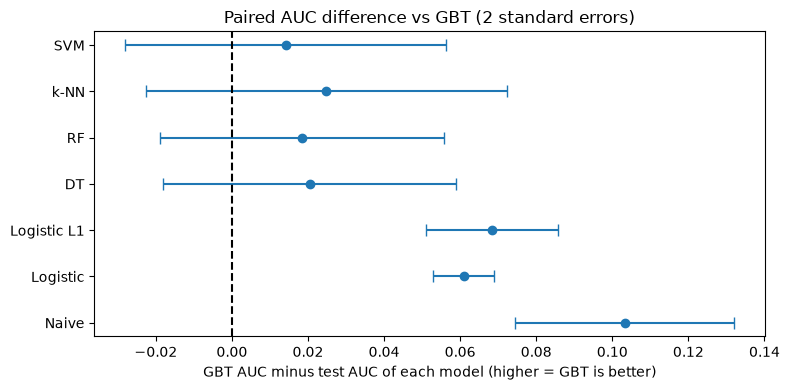

In [50]:
from scipy.stats import ttest_rel

# Paired t-test (as in the labs): is the best model (highest mean test AUC) really better than each of the others?
# The splits reuse the same students, so the p-values are too small: we only use them as a sanity check
auc = {name: classification_scores[name].values for name in classification_names}
best_class = max(auc, key=lambda name: auc[name].mean())
print('Best model on AUC:', best_class)

for name in auc:
    if name != best_class:
        diff = auc[best_class] - auc[name]
        p = ttest_rel(auc[best_class], auc[name]).pvalue
        print(f'{name:12} mean diff = {diff.mean():.3f}   p = {p:.4f}')

# Paired differences against the best model, with error bars of 2 standard errors
others = [name for name in classification_names if name != best_class]
n = len(classification_scores)
mean_diffs = [(auc[best_class] - auc[name]).mean() for name in others]
margins = [2 * (auc[best_class] - auc[name]).std(ddof=1) / np.sqrt(n) for name in others]

plt.figure(figsize=(8, 4))
plt.errorbar(mean_diffs, range(len(others)), xerr=margins, fmt='o', capsize=4)
plt.yticks(range(len(others)), others)
plt.axvline(0, color='black', linestyle='--')
plt.xlabel(f'{best_class} AUC minus test AUC of each model (higher = {best_class} is better)')
plt.title(f'Paired AUC difference vs {best_class} (2 standard errors)')
plt.tight_layout()
plt.show()

# Stage 4: Feature Exploration

We want to see which predictors matter most for `final_grade_pct`. Everything here comes from the main regression experiment, so nothing is refitted.

- **Permutation importance** for Lasso, decision tree, random forest, GBT and GAM: shuffle one predictor in the test set and see how much the RMSE goes up. The error bars are the SD over the 20 experiments.
- **Lasso**: how often each predictor was kept (non-zero coefficient), and the mean and SD of its coefficient.

The first plot shows how far ahead `previous_year_grade_pct` is, using the permutation importance averaged over the five models. In the per-model plots after it, the bars are coloured by group (socioeconomic, effort, technology, household, school/demographics). `previous_year_grade_pct` is left out of the per-model plots because it is much more important than everything else and squashes the other bars (its Lasso coefficient is still shown in the table).

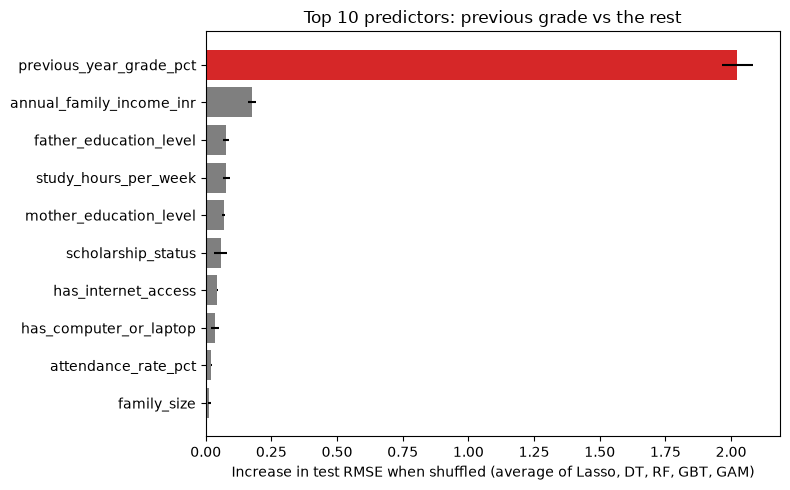

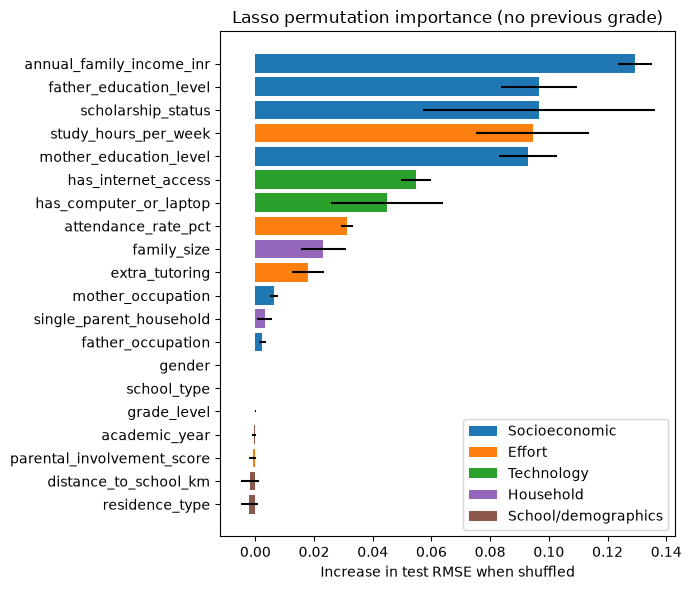

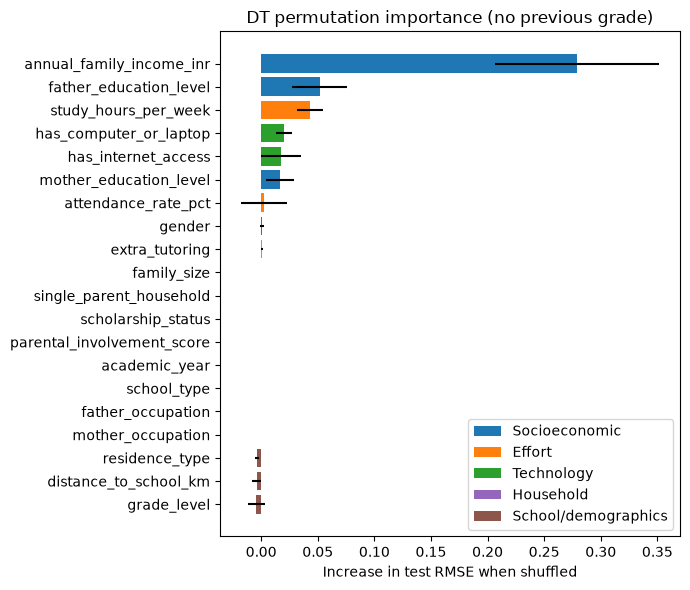

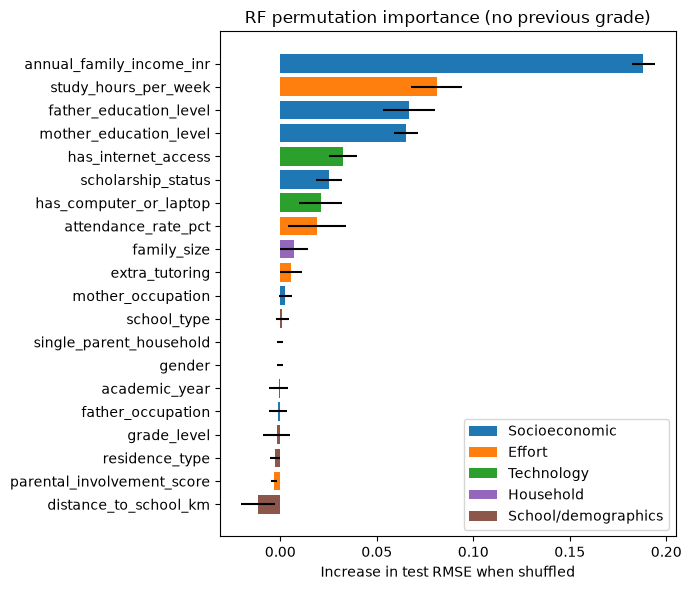

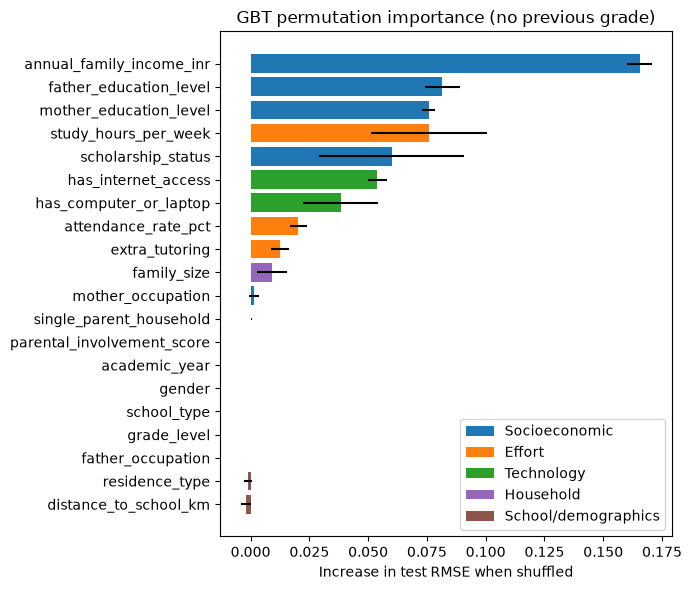

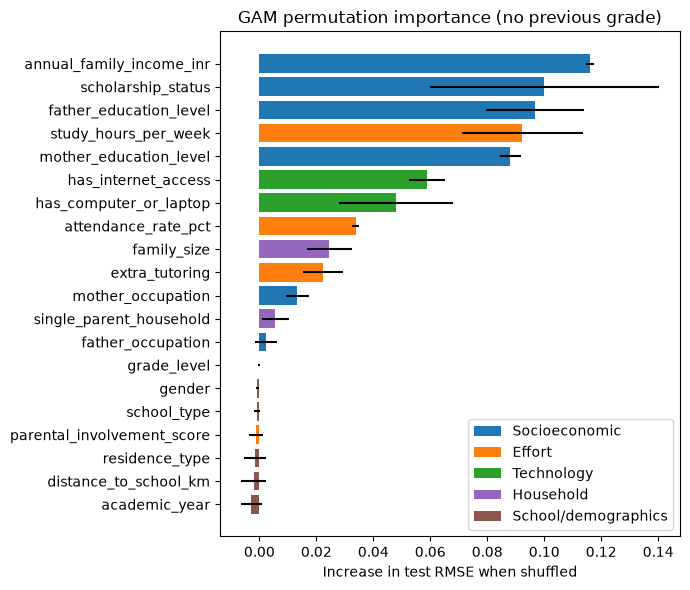

How often the Lasso kept each predictor (out of the 3 experiments)
extra_tutoring                1.000000
has_computer_or_laptop        1.000000
mother_education_level        1.000000
father_education_level        1.000000
mother_occupation             1.000000
father_occupation             1.000000
residence_type                1.000000
parental_involvement_score    1.000000
study_hours_per_week          1.000000
scholarship_status            1.000000
has_internet_access           1.000000
single_parent_household       1.000000
family_size                   1.000000
annual_family_income_inr      1.000000
previous_year_grade_pct       1.000000
attendance_rate_pct           1.000000
grade_level                   0.666667
academic_year                 0.333333
distance_to_school_km         0.333333
gender                        0.000000
school_type                   0.000000
dtype: float64


Lasso coefficients, mean and SD over the 3 experiments (per 1 SD for numeric and ordinal columns,

In [51]:
# Feature importance over the 20 experiments (collected in the main regression loop, so nothing is refitted here)
importance_df = pd.DataFrame(importance_records)

# Plot 1: previous grade compared with the other predictors
# Average the 5 models in each experiment, then take the mean and SD over the 20 experiments
avg_importance = importance_df.groupby('experiment')[PREDICTOR_COLS].mean()
top10 = avg_importance.mean().sort_values().tail(10)
top10_sd = avg_importance[top10.index].std()
top_colours = ['tab:red' if col == 'previous_year_grade_pct' else 'tab:gray' for col in top10.index]

plt.figure(figsize=(8, 5))
plt.barh(y=range(len(top10)), width=top10, xerr=top10_sd, tick_label=top10.index, color=top_colours)
plt.xlabel('Increase in test RMSE when shuffled (average of Lasso, DT, RF, GBT, GAM)')
plt.title('Top 10 predictors: previous grade vs the rest')
plt.tight_layout()
plt.show()

# Group the predictors so the bars can be coloured by group
groups = {
    'Socioeconomic':       ['annual_family_income_inr', 'father_education_level', 'mother_education_level',
                            'father_occupation', 'mother_occupation', 'scholarship_status'],
    'Effort':              ['study_hours_per_week', 'attendance_rate_pct', 'extra_tutoring', 'parental_involvement_score'],
    'Technology':          ['has_internet_access', 'has_computer_or_laptop'],
    'Household':           ['family_size', 'single_parent_household'],
    'School/demographics': ['school_type', 'residence_type', 'distance_to_school_km', 'grade_level', 'academic_year', 'gender'],
}
colours = {
    'Socioeconomic': 'tab:blue', 
    'Effort': 'tab:orange', 
    'Technology': 'tab:green',
    'Household': 'tab:purple', 
    'School/demographics': 'tab:brown'
}

group_of = {}
for group, cols in groups.items():
    for col in cols:
        group_of[col] = group

# previous_year_grade_pct is much bigger than everything else, so we leave it out of the plots
plot_cols = [col for col in PREDICTOR_COLS if col != 'previous_year_grade_pct']

for model_name in ['Lasso', 'DT', 'RF', 'GBT', 'GAM']:
    imp = importance_df[importance_df['model'] == model_name][plot_cols]
    means = imp.mean().sort_values()
    stds = imp[means.index].std()
    bar_colours = [colours[group_of[col]] for col in means.index]

    plt.figure(figsize=(7, 6))
    plt.barh(y=range(len(means)), width=means, xerr=stds, tick_label=means.index, color=bar_colours)
    for group, colour in colours.items():
        plt.barh(0, 0, color=colour, label=group)    # empty bars, only used for the legend
    plt.legend(loc='lower right')
    plt.xlabel('Increase in test RMSE when shuffled')
    plt.title(model_name + ' permutation importance (no previous grade)')
    plt.tight_layout()
    plt.show()

# How often the Lasso kept each predictor (out of the 20 experiments)
lasso_kept = pd.DataFrame(lasso_selection_records).drop(columns='experiment')
print(f"How often the Lasso kept each predictor (out of the {NUMBER_OF_EXPERIMENTS} experiments)")
print(lasso_kept.mean().sort_values(ascending=False))
print("\n")

# Lasso coefficients, mean and SD over the 20 experiments (per 1 SD for numeric and ordinal columns, per 'yes' for 0/1 and one-hot columns)
lasso_coefs = pd.DataFrame(lasso_coefficient_records).drop(columns='experiment')
coef_table = pd.DataFrame({'mean': lasso_coefs.mean(), 'sd': lasso_coefs.std()})
coef_table = coef_table.sort_values('mean', key=abs, ascending=False)
print(f"Lasso coefficients, mean and SD over the {NUMBER_OF_EXPERIMENTS} experiments (per 1 SD for numeric and ordinal columns, per 'yes' for 0/1 and one-hot columns)")
print(coef_table.head(15).round(3))

### GAM: Effect Sizes

A GAM adds up one effect per predictor, so each predictor’s effect can be read straight from the fitted model. The table uses the tuned GAM from the final repeat and shows the spread of each effect over the middle 95% of its training students (in grade points), plus each term’s EDF and pygam’s approximate p-value (the same numbers as gam.summary()). EDF ≈ 1 means the term is effectively a straight line.

In [52]:
# Effect size of each term, from the tuned GAM of the final repeat
gam_best = gam_search.best_estimator_
gam_model = gam_best.named_steps["model"]
gam_X = gam_best.named_steps["prep"].transform(X_train)[
    gam_model.columns_
].to_numpy(dtype=float)

edof_per_coef = gam_model.gam_.statistics_["edof_per_coef"]
p_values = gam_model.gam_.statistics_["p_values"]

effect_rows = {}
start = 0

for i, col in enumerate(gam_model.columns_):
    term = gam_model.gam_.terms[i]
    contribution = gam_model.gam_.partial_dependence(term=i, X=gam_X)
    low, high = np.percentile(contribution, [2.5, 97.5])

    effect_rows[col] = {
        "term": type(term).__name__.replace("Term", ""),
        "effect range": high - low,
        "EDF": edof_per_coef[start:start + term.n_coefs].sum(),
        "p-value": p_values[i],
    }
    start += term.n_coefs

effect_table = pd.DataFrame(effect_rows).T.sort_values(
    "effect range",
    ascending=False,
)
print("GAM effect sizes (final repeat). Effect range = spread of the effect over the middle 95% of training students, in grade points")
print(
    effect_table.to_string(
        formatters={
            "effect range": "{:.2f}".format,
            "EDF": "{:.2f}".format,
            "p-value": "{:.3g}".format,
        }
    )
)

GAM effect sizes (final repeat). Effect range = spread of the effect over the middle 95% of training students, in grade points
                              term effect range  EDF  p-value
previous_year_grade_pct     Spline        18.01 2.13 1.11e-16
annual_family_income_inr    Spline         4.67 3.46 6.91e-12
father_education_level      Factor         4.50 5.90 6.14e-12
mother_education_level      Factor         3.52 5.91 2.66e-07
scholarship_status          Factor         3.42 1.97 1.11e-16
study_hours_per_week        Spline         2.90 1.80 2.03e-11
attendance_rate_pct         Spline         2.13 2.53   0.0347
family_size                 Linear         1.55 0.99 6.78e-06
has_internet_access         Factor         1.53 0.99 7.09e-13
has_computer_or_laptop      Factor         1.50 0.99 9.92e-13
mother_occupation           Factor         1.03 7.91     0.06
extra_tutoring              Factor         0.96 0.99 0.000236
father_occupation           Factor         0.74 6.93    0.459
singl

**GAM effect sizes findings:**

- Across the middle 95% of students, previous grade moves the GAM’s prediction by about 18 grade points. Income, father’s and mother’s education, and scholarship move it by about 4 each; study hours by 3 and attendance by about 2.3. Each yes/no flag (computer, internet, tutoring, single parent) is worth about 1–1.5 points.

- Distance, gender, school type, residence, academic year, grade level, and father’s occupation each move it by under 1 point and are not significant (p > 0.3), matching their near-zero permutation importance.

### Feature Selection: Conclusion

- **Previous grade is by far the strongest predictor.** Its Lasso coefficient is about 4.5 grade points per SD, around four times the next largest (family income, about 1.0). Past performance already captures most of what makes a student strong or weak.

- **After previous grade, socioeconomic background matters most.** The top of every plot is mostly blue. Family income is ranked first by all five models, and parents' education and scholarship status are near the top for Lasso, RF, GBT and GAM. Study hours is the only effort variable close to the top, followed by the two technology variables (internet and computer access). Attendance, tutoring and family size have smaller but consistent effects.

- **School and demographic factors add almost nothing.** School type, residence, distance to school, grade level, academic year and gender are close to zero in every model, and the Lasso drops most of them in most experiments (gender is kept in 10% of experiments, school type in 15%).

- **The four models agree.** Lasso, DT, RF, GBT and GAM make very different assumptions but give almost the same ranking, and the error bars are small compared with the top bars, so the top predictors are stable across the 20 splits. The main difference is that the tree models put more weight on income alone (the single decision tree puts almost everything there), while the Lasso spreads it over income, scholarship and parents' education. These are correlated, so a tree can use income as a stand-in for the whole SES group. The GAM's bars are almost the same as Lasso's, as expected for a model whose fitted effects are close to straight lines.

- **Link to the experiment results.** This matches the regression experiment. The Lasso had the lowest test RMSE, OLS and Ridge could not be told apart from it, and the more flexible RF and GBT were significantly worse. The tuned GBT also chose trees of depth 1, which can only add up separate effects for each predictor with no interactions. Putting this together, final grades look like the sum of a few separate effects (previous grade first, then family SES, study time and technology access), each moving the grade by a roughly fixed amount. The flexible models find the same predictors but gain nothing from fitting curves or interactions, so a linear model with these predictors is enough, and its coefficients can be read directly. The clustering in the next section points the same way: SES and device access add up rather than interact.

- **Caveats.** These importances are predictive, not causal (for example, tutoring may partly reflect motivation). Because income, parents' education and scholarship are correlated, shuffling one at a time understates how much SES matters as a group. Bars near zero overlap with their error bars, so their order should not be read into.

# Stage 5: Unsupervised Learning Analysis - K-Means Clustering (Socioeconomic features)

Exploratory Data Analysis: Cluster students on socioeconomic features only, then check whether the groups differ in effort and grades.

### Step 1: Select features

In [53]:

km_df = GroupImputer().fit_transform(df)
km_df = km_df.drop(columns="family_income_bracket")

# ======= Ordinal encoding education ====== #
edu_rank = {
    "No Formal Education": 0,
    "Primary": 1,
    "Secondary": 2,
    "Higher Secondary": 3,
    "Bachelor's Degree": 4,
    "Master's Degree": 5,
    "Doctorate": 6
}

km_df['father_edu'] = km_df['father_education_level'].map(edu_rank)
km_df['mother_edu'] = km_df['mother_education_level'].map(edu_rank)

# 'Unknown' doesn't map to a number, fill with median
km_df['father_edu'] = km_df["father_edu"].fillna(km_df['father_edu'].median())
km_df['mother_edu'] = km_df["mother_edu"].fillna(km_df['mother_edu'].median())

# ======= Log income ====== #
km_df['log_income'] = np.log(km_df['annual_family_income_inr'])

# ======= Do household columns track SES? ===== #
household = ['single_parent_household', 'family_size', 'num_siblings']

print("Correlation of household columns with SES features:")
display(km_df[household + ['log_income', 'father_edu', 'mother_edu']].corr().loc[household, ['log_income', 'father_edu', 'mother_edu']].round(3))

# ======= SES columns ====== #
ses_cols = ['log_income', 'father_edu', 'mother_edu']

print("Description of SES columns we are going to cluster on:")
display(km_df[ses_cols].describe().round(2))

Correlation of household columns with SES features:


,log_income,father_edu,mother_edu
single_parent_household,-0.003,0.014,0.003
family_size,0.002,0.008,0.013
num_siblings,0.001,0.009,0.009


Description of SES columns we are going to cluster on:


,log_income,father_edu,mother_edu
count,12000.00,12000.00,12000.00
mean,12.83,2.67,2.70
std,0.99,1.52,1.52
min,11.00,0.00,0.00
25%,12.17,2.00,2.00
50%,12.77,3.00,3.00
75%,13.39,4.00,4.00
max,16.79,6.00,6.00


Why these features:
- SES is usually measured by income, education and occupation. We've included income and education directly. 
- Parents' occupation was left out as it has no natural order, and being a 'Homemaker' (the most common for mothers) goes with the highest median income, so it can't be ranked sensibly
- `has_internet_access` and `has_computer_or_laptop` were left out of the clustering. They are 0/1 columns, and in a separate experiment we conducted, K-Means tended to split along those values since everyone with the same value sat at exactly the same point. They ended up driving the clusters. Leaving them out allows K-Means to find the SES boundary by itself.

- Other columns were checked and left out:
    - `family_income_bracket` is a banded version of income column

    - `scholarship_status` is a result of low SES, not a measure of it
    - `single_parent_household`, `family_size` and `num_siblings` have almost no correlation with income or education (r approx 0)
    - `distance_to_school_km` mostly reflects rural vs urban.
- `school_type`, `residence_type` and the grade columns are kept out on purpose, so they can be compared between clusters afterwards

### Step 2: Scale features and choose k

We use Inertia & Silhouette to determine which k to pick.

Inertia
- Measures how compact the clusters are
- Lower is better for compactness, but inertia generally increases as we add more clusters, even if the extra clusters aren't meaningful.
- To choose no. clusters, we plot inertia against K and look for an elbow point after which adding clusters brings diminishing returns

Silhouette
- The silhouette score tells us whether each point is closer to its own cluster or other clusters
- Near 1: Well within its cluster and separated from others
- Near 0: Near a boundary between clusters
- Below 0: Closer on average to another cluster than its own

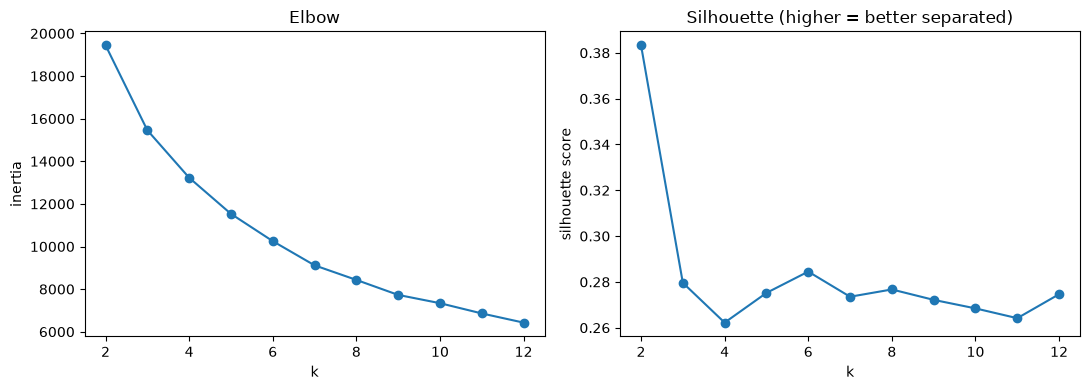

In [54]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

km_X = StandardScaler().fit_transform(km_df[ses_cols])

inertias = []
sil_scores = []

for k in range(2, 13):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(km_X)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(km_X, km.labels_, sample_size=3000, random_state=42))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(range(2, 13), inertias, marker="o")
axes[0].set_xlabel("k")
axes[0].set_ylabel("inertia")
axes[0].set_title("Elbow")

axes[1].plot(range(2, 13), sil_scores, marker="o")
axes[1].set_xlabel("k")
axes[1].set_ylabel("silhouette score")
axes[1].set_title("Silhouette (higher = better separated)")

plt.tight_layout()
plt.show() 

We pick k = 2
- Silhouette has one clear peak at k = 2 (0.37). It then drops to 0.27 at k = 3 and stays flat at 0.26 to 0.27 for every k up to 12, so no other number of clusters stands out.

- The elbow plot doesn't help: inertia drops smoothly with no clear bend, so the choice rests on the silhouette.

- With only 3 continuous features, there are no 0/1 columns to inflate the silhouette score, so the higher value really does mean better-separated groups.

- k = 2 is also the simplest result to interpret: a lower-SES and a higher-SES group.

### Step 3: Fit k = 2 and profile the clusters

Clusters are numbered so 0 = lower SES and 1 = higher SES.

Cluster counts breakdown:


cluster
0    6903
1    5097
Name: count, dtype: int64

Cluster means breakdown:


,log_income,father_edu,mother_edu
cluster,,,
0,12.28,1.78,1.79
1,13.57,3.89,3.94


Cluster income breakdown:


cluster
0    228061.0
1    692614.0
Name: annual_family_income_inr, dtype: float64

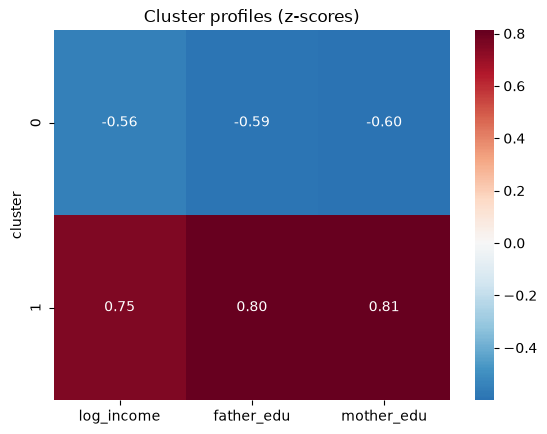

In [55]:
km = KMeans(n_clusters=2, n_init=10, random_state=42)
km_df["cluster"] = km.fit_predict(km_X)

# Renumber so 0 = lower income and 1 = higher
income_rank = km_df.groupby("cluster")["log_income"].mean().rank().astype(int) - 1
km_df["cluster"] = km_df["cluster"].map(income_rank)

print("Cluster counts breakdown:")
display(km_df["cluster"].value_counts().sort_index())

print("Cluster means breakdown:")
display(km_df.groupby('cluster')[ses_cols].mean().round(2))

print("Cluster income breakdown:")
display(km_df.groupby('cluster')['annual_family_income_inr'].median())

import seaborn as sns

# average z-score per cluster, 0 = overall average
km_X_df = pd.DataFrame(km_X, columns=ses_cols)
km_X_df["cluster"] = km_df["cluster"].values
profile = km_X_df.groupby("cluster").mean()

sns.heatmap(profile, annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Cluster profiles (z-scores)")
plt.show()

### Step 4: Compare clusters on grades, digital access and background

### Grades

Average grades and effort by cluster:


,final_grade_pct,grade_change,study_hours_per_week,attendance_rate_pct,extra_tutoring,parental_involvement_score
cluster,,,,,,
0,63.68,4.61,13.78,84.81,0.19,3.15
1,71.37,4.63,15.30,87.25,0.29,3.38


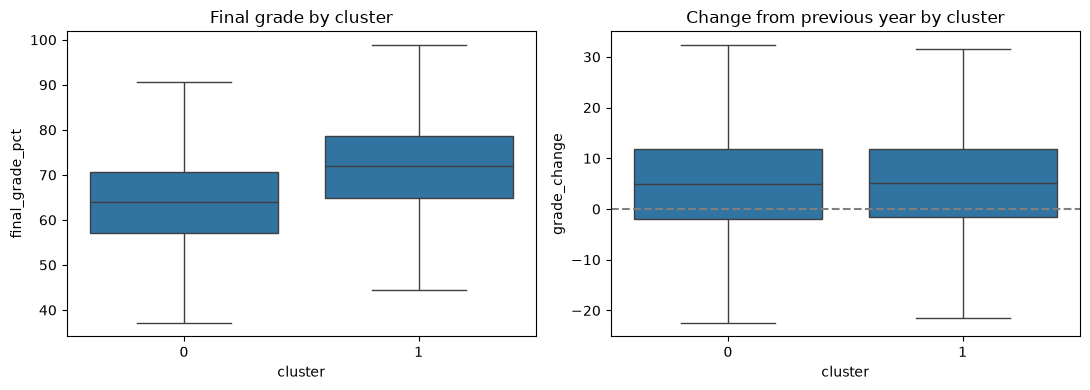

In [56]:
km_df["grade_change"] = km_df["final_grade_pct"] - km_df["previous_year_grade_pct"]

print("Average grades and effort by cluster:")
display(
    km_df.groupby("cluster")[
        [
            "final_grade_pct",
            "grade_change",
            "study_hours_per_week",
            "attendance_rate_pct",
            "extra_tutoring",
            "parental_involvement_score",
        ]
    ]
    .mean()
    .round(2)
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.boxplot(
    data=km_df,
    x="cluster",
    y="final_grade_pct",
    showfliers=False,
    ax=axes[0],
)
axes[0].set_title("Final grade by cluster")

sns.boxplot(
    data=km_df,
    x="cluster",
    y="grade_change",
    showfliers=False,
    ax=axes[1],
)
axes[1].axhline(0, color="grey", linestyle="--")
axes[1].set_title("Change from previous year by cluster")

plt.tight_layout()
plt.show()

### Digital Access

Internet and computer access weren't used for clustering, so we check how access differs between the SES groups and how it relates to grades within each group

In [57]:
# 0 = neither, 1 = internet or computer, 2 = both
km_df["devices"] = (
    km_df["has_internet_access"].astype(int)
    + km_df["has_computer_or_laptop"]
)

print("Share of each cluster with internet / a computer")
display(
    km_df.groupby("cluster")[
        ["has_internet_access", "has_computer_or_laptop"]
    ].mean().round(2)
)

print("Average final grade by cluster and number of devices")
display(
    pd.crosstab(
        km_df["cluster"],
        km_df["devices"],
        values=km_df["final_grade_pct"],
        aggfunc="mean",
    ).round(1)
)

print("Number of students by cluster and number of devices")
display(pd.crosstab(km_df["cluster"], km_df["devices"]))

Share of each cluster with internet / a computer


,has_internet_access,has_computer_or_laptop
cluster,,
0,0.44,0.34
1,0.58,0.51


Average final grade by cluster and number of devices


devices,0,1,2
cluster,,,
0,61.8,64.5,66.0
1,68.5,71.0,73.9


Number of students by cluster and number of devices


devices,0,1,2
cluster,,,
0,2657,3090,1156
1,1152,2323,1622


### Background

In [58]:
# Rows add up to 1
print("School type (share of each cluster)")
display(
    pd.crosstab(
        km_df["cluster"],
        km_df["school_type"],
        normalize="index",
    ).round(2)
)

print("Residence type (share of each cluster)")
display(
    pd.crosstab(
        km_df["cluster"],
        km_df["residence_type"],
        normalize="index",
    ).round(2)
)

print("Scholarship status (share of each cluster)")
display(
    pd.crosstab(
        km_df["cluster"],
        km_df["scholarship_status"],
        normalize="index",
    ).round(2)
)

School type (share of each cluster)


school_type,Government,Government-Aided,Private-Unaided
cluster,,,
0,0.45,0.2,0.35
1,0.45,0.2,0.35


Residence type (share of each cluster)


residence_type,Rural,Semi-Urban,Urban
cluster,,,
0,0.35,0.23,0.42
1,0.36,0.22,0.42


Scholarship status (share of each cluster)


scholarship_status,Full,No Scholarship,Partial
cluster,,,
0,0.10,0.69,0.20
1,0.04,0.89,0.07


### Findings so far

**Cluster structure**

- There is one natural split in income and parents’ education: **lower SES** (cluster 0, 57% of students, median income 230k, parents’ education around primary to secondary level) and **higher SES** (cluster 1, 43%, median income 690k, parents’ education around higher secondary to a bachelor’s degree).

- This is the clearest structure found (silhouette 0.37). It is still moderate, so the groups are more of a continuum rather than completely separate types.

**Grades**

- Higher-SES students average about 8 points higher (71.4 vs. 63.7), and their whole grade range is shifted up.

- Both groups improved on the previous year by about the same amount (+4.6), so the higher-SES group starts ahead rather than pulling further ahead.

- Effort differs only a little: 13.8 vs. 15.3 study hours per week, and 85% vs. 87% attendance. Tutoring is the clearest difference: 29% vs. 19%.

**Digital access**

- Higher-SES students are more likely to have devices: 58% have internet and 51% have a computer, compared with 44% and 34% in the lower-SES group.

- Within both groups, each extra device goes with about 2 to 3 more points:
  - Lower SES: 61.8 (neither) → 64.4 (one) → 66.0 (both)

  - Higher SES: 68.5 → 71.1 → 73.8
- At every level of access, higher-SES students are about 7 to 8 points ahead.
- SES and digital access look roughly **additive**: background is the bigger factor, and devices go with a similar extra gain in both groups.
- A lower-SES student with both devices (66.0) still averages below a higher-SES student with neither (68.5).

**Background**

- School type and residence are almost identical in both groups (about 45% government schools and about 35% rural), so neither separates the SES groups in this data.

- Scholarships go mostly to lower-SES students: 30% have one (full or partial), compared with 11% of the higher-SES group.

### Step 5: Visualize Clusters in 2D (PCA)

PCA reduces the 3 scaled features into 2 components so the clusters can be plotted. With only 2 clusters, a single scatter plot colored by cluster is readable

Share of variance explained by each component


PC1    0.679
PC2    0.164
dtype: float64

What each component is made of


,PC1,PC2
log_income,0.57,0.82
father_edu,0.58,-0.47
mother_edu,0.58,-0.34


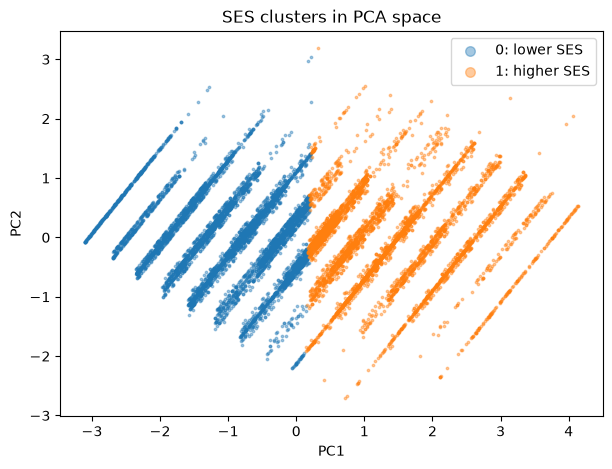

In [59]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
pcs = pca.fit_transform(km_X)

print("Share of variance explained by each component")
display(
    pd.Series(
        pca.explained_variance_ratio_,
        index=["PC1", "PC2"],
    ).round(3)
)

print("What each component is made of")
display(
    pd.DataFrame(
        pca.components_.T,
        index=ses_cols,
        columns=["PC1", "PC2"],
    ).round(2)
)

lower = km_df["cluster"].values == 0

plt.figure(figsize=(7, 5))
plt.scatter(
    pcs[lower, 0], pcs[lower, 1],
    s=3, alpha=0.4, label="0: lower SES",
)
plt.scatter(
    pcs[~lower, 0], pcs[~lower, 1],
    s=3, alpha=0.4, label="1: higher SES",
)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(markerscale=4)
plt.title("SES clusters in PCA space")
plt.show()

Findings for PCA
- Two components explain 84% of the variance. PC1 (67%) is overall SES: income and both parents’ education load about equally. PC2 (17%) mostly separates income from education, for example, families with high income but less-educated parents.

- The two clusters split cleanly along PC1: lower SES on the left, higher SES on the right. They meet in the middle without a gap, which fits the moderate silhouette: the split is a boundary drawn through a continuum.

- The points fall in diagonal stripes because parents’ education is a whole number from 0 to 6. Each stripe is one combination of father’s and mother’s education, and income spreads students along it.

# Stage 6: Limitations (TODO: move this to report)

### Limitation 1: Minor leakage from the hyperparameter pilot

The coarse-to-fine pilot runs once on a single 85% training split to narrow each regression model's grid. The main experiment then uses a different random split in each repeat, so on average about 85% of the rows in each later test set were already used by the pilot.

We expect the leakage effect to be small because:

- The pilot only decides the short list of hyperparameter values each model can choose from. Within each repeat, tuning, preprocessing and fitting still use only that repeat's 85% training data, so a model is never fitted on its own test rows.
- Any optimism can only favour the tuned models. Naive and OLS have no hyperparameters, so they are not affected.
- The classification experiment has no pilot, so it is not affected.

Reserving separate rows only for the pilot would remove the leak, but would leave less data for all 20 repeats. We keep the current setup and report this as a limitation.

### Limitation 2: An uneven grade distribution with a tail of sudden, unpredictable drops

Both experiments are limited by the same feature of the data: a small group of students whose final grade falls far below what their background and previous grade suggest. This sets a floor on the regression RMSE and a ceiling on the classification AUC that no model in our study can get past. The numbers below come from out-of-fold Lasso predictions (5-fold CV) on the full dataset.

**The grades are unevenly spread, and the changes are one-sided**

- Half of the students (51%) are in grade class C, while only 1.8% are F and 1.7% are A.
- From last year to this year, 69 students fell by more than 40 points, but only 1 rose by that much. 29 fell by more than 50 points, and none rose by that much.
- The residuals have a long lower tail (skew −1.4, excess kurtosis 6.4). 153 students are more than 3 SD from their prediction, against about 32 expected if the errors were normal, and 98% of them are *below* their prediction. MAE/RMSE is 0.73, compared with 0.80 for normal errors.
- A two-group Gaussian mixture (Week 12) fits the residuals much better than a single normal distribution (BIC 86,380 vs 88,446). The main group has an SD of 7.7 points. The second group contains 277 students (2.3%) who averaged 63 last year and were predicted 68, but scored 36.

**Effect on the regression experiment**

- These 2.3% of students produce **34% of the squared error**. For everyone else the RMSE is 7.9, compared with 9.6 overall, so our RMSE of about 9.6 is largely set by the drops.
- The drops cannot be predicted from the data. Predicting who is in the drop group gives a CV AUC of 0.50 (logistic) and 0.56 (GBT), and the drop rate is 2.0–2.6% across every academic year, school type, gender and residence type.
- They inflate the error but barely change the fitted model: the OLS coefficients with and without the drop group correlate at 0.97 (previous grade: 4.5 vs 4.7 per SD), and only the intercept is pulled down, by about 0.7 points.
- A different loss does not help. Median regression (absolute error, Week 9) gets the same RMSE (9.66) and MAE (7.04) as the Lasso.
- In the actual vs. predicted plots, the drop group is the cloud of points well below the diagonal at low actual grades. The plots also show regression to the mean: by actual grade class, the mean residual is −36 for F and +15 for A, but by predicted grade it is within ±0.5 everywhere, so the models are not biased against low or high scorers.

**Effect on the classification experiment**

- The at-risk group is mostly made of these drops: 86% of at-risk students are in the drop group, and 78% had a previous grade of at least 50. Their mean predicted grade is 65, and only 10 of the 218 have a predicted grade below 50. Without the drops, the at-risk rate would fall from 1.8% to about 0.2%.
- This puts a ceiling on AUC. We simulated the best possible case, where each student's expected grade is known exactly and only the noise is random:

| Noise in the simulation | Best possible AUC |
|---|---|
| Our real residuals, including the drops | **0.64** |
| Normal noise with the same SD (9.6) | 0.87 |

  Ranking students by their predicted grade gives an AUC of 0.55, and our best classifiers reach around 0.60, so they are already close to the 0.64 ceiling.
- With only about 44 at-risk students per test set, one split's AUC has a standard error of about 0.045, so differences between classifiers smaller than about 0.04 cannot be resolved (see the paired t-tests).

**What this means**

The remaining error behaves like random shocks that are unrelated to every predictor, not like a pattern a better model could learn. This is consistent with the flexible models not beating the linear ones in the regression, and it may indicate that the drops were added to the data independently of the other columns. Our RMSE and AUC should be read against these limits: the typical student is predicted to within about 8 points, and no model can reliably flag at-risk students from background data. In practice, a school would need information collected during the year, such as mid-term grades or changes in attendance, to catch these drops.